<a id="top" name="top"></a>
# Lab01 — случайные величины в работе ионного канала
**Направление:** ИнфоХимия (исследование) · КТвД (оформление, доп. задание)
**Данные:** симулированные токи ионных каналов, Zenodo, запись 8288407 (папка `high / White Gaussian noise / k1=100-k2=100`) · доп. датасет КТвД: вина UCI Wine (`sklearn.datasets.load_wine`)

> **Как читать ноутбук.** Код в ячейках скрыт, видны только результаты. Из архива на Zenodo скачивается только один нужный файл, а не весь архив. Критерии оценивания и где они выполнены — в [разделе 14](#s14). Все правки КТвД в работе ИнфоХимии помечены значком ✏️ и собраны в [журнале правок](#s17).
>


<a id="toc" name="toc"></a>
## Содержание

**Lab01 — спринт 1**
- [0. Введение в тематику](#s0)
- [1. Датасет, случайные величины, обозначения](#s1)
- [2. Случайная величина 1: время в открытом состоянии $T_{open}$](#s2) — [2.1 Описание](#s2-1) · [2.2 Разведочный анализ и распределение](#s2-2) · [2.3 Доказательство случайности](#s2-3) · [2.4 Состоятельность оценок](#s2-4)
- [3. Случайная величина 2: время в закрытом состоянии $T_{closed}$](#s3) — [3.1 Описание](#s3-1) · [3.2 Разведочный анализ и распределение](#s3-2) · [3.3 Доказательство случайности](#s3-3) · [3.4 Состоятельность оценок](#s3-4)
- [4. Независимость $T_{open}$ и $T_{closed}$](#s4)
- [5. Случайная величина 3: амплитуда тока $I_{open}$](#s5) — [5.1 Описание](#s5-1) · [5.2 Разведочный анализ и распределение](#s5-2) · [5.3 Состоятельность оценок](#s5-3)
- [6. Генеральная совокупность и выборка](#s6)
- [7. Математическая база распределения](#s7)
- [8. Проверка гипотезы](#s8) — [8.1 Дополнительные гипотезы](#s8-1)
- [9. Итоги спринта 1 и таблица оценок](#s9)

**Lab01 — спринт 2**
- [10. Датчик 1: показательное распределение $\mathrm{Exp}(\lambda)$](#s10) — [10.1 Описание](#s10-1) · [10.2 Математическое обоснование](#s10-2) · [10.3 Код](#s10-3) · [10.4 Тесты](#s10-4) · [10.5 Итоги](#s10-5)
- [10.6 Датчик 2: нормальное распределение $\mathcal N(\mu,\sigma^2)$ для $I_{open}$](#s10-6)
- [10.7 Исследование алгоритмов датчиков](#s10-7)
- [11. Итоги спринта 2, итоговые метрики и таблица оценок](#s11)

**Часть КТвД**
- [12. Доп. датасет: химический состав вин](#s12) — [12.1 Описание](#s12-1) · [12.2 Разведочный анализ](#s12-2) · [12.3 Случайность](#s12-3) · [12.4 Независимость](#s12-4) · [12.5 Вывод](#s12-5)
- [13. Интерактивный генератор](#s13)
- [14. Критерии оценивания](#s14)
- [15. Список литературы](#s15)
- [16. Выгрузка данных для сайта](#s16)
- [17. Журнал правок (КТвД)](#s17) — что исправлено и добавлено в работе ИнфоХимии, авторство разделов


<a id="s0" name="s0"></a>
## 0. Введение в тематику

В основе нашего исследования лежит технология **оптогенетики**. Суть эксперимента такова: в нейроны мыши с помощью вируса встраивают специальный белок **Channelrhodopsin-2 (ChR2)**. Этот белок является ионным каналом одновременно с этим может реагировать на свет.

К голове мыши прикрепляют тонкое оптоволокно, через которое подают световые импульсы. Когда свет достигает белка, тот меняет свою форму («открывается»), и через него в нейрон начинают проходить ионы. Нейрон возбуждается, что приводит к выбросу дофамина. В эксперименте это связано с нажатием кнопки: мышь нажимает на неё, получает «награду» (ощущение радости от выброса дофамина) и начинает нажимать снова и снова, когда захочет.

*Интересный факт:* в 2026 году Нобелевскую премию по медицине получили за подобное открытие, ученые смогли активировать уже конкретные нейроны с помощью вспышки света в мозге мыши. Благодаря именно этой отрасли в будущем ученые смогут **восстанавливать зрение**, создавать импланты для **восстановления слуха** и **лечить неизлечимые болезни**, такие как *эпилепсия*, *болезнь Паркинсона* и другие неврологические заболевания. 👽

**Важно про данные.** Оптогенетика и ChR2 здесь — мотивация, то есть причина, почему нам вообще интересно, сколько живёт открытый канал. Сами данные — не запись с ChR2 и не эксперимент со светом. Это компьютерная модель обобщённого ионного канала с двумя состояниями: он сам, без внешнего сигнала, переключается между «закрыт» и «открыт», и интенсивности переходов в обе стороны одинаковы: $k_1 = k_2 = 100\ \text{с}^{-1}$, а к току добавлен белый гауссов шум. Поэтому в наших данных случайно и открытие, и закрытие.

<sub>✏️ Правка КТвД № 12 — см. [журнал правок](#s17).</sub>

[↑ к содержанию](#toc)

> ✏️ **Правка КТвД № 10.** «психические заболевания» → «неврологические»: эпилепсия и болезнь Паркинсона — неврологические заболевания. Подробно — [журнал правок](#s17).


<a id="s1" name="s1"></a>
## 1. Датасет, случайные величины, обозначения

В качестве источника данных выбран открытый датасет симулированных токов ионных каналов (Zenodo, запись 8288407). Датасет основан на двухсостояниевой модели гейтинга (закрыт/открыт) и содержит временные ряды с метками состояний (0/1) и значениями тока.

Для анализа выбраны три случайные величины:
1. **СВ 1 ($T_{open}$): Время жизни в открытом состоянии** — длины непрерывных отрезков, где канал открыт (метка состояния 1).
2. **СВ 2 ($T_{closed}$): Время жизни в закрытом состоянии** — длины непрерывных отрезков, где канал закрыт (метка состояния 0).
3. **СВ 3 ($I_{open}$): Амплитуда тока в открытом состоянии** — значения тока, соответствующие открытому состоянию канала.

**Обозначения и единицы (едины для всего ноутбука)**

| Обозначение | Смысл | Единицы |
|---|---|---|
| $T_{open},\ T_{closed}$ | время жизни канала в открытом / закрытом состоянии | с |
| $I_{open}$ | амплитуда тока в открытом состоянии | пА |
| $\lambda,\ \hat\lambda = 1/\bar x$ | интенсивность переходов и её оценка | с$^{-1}$ |
| $\bar x,\ s^2,\ s$ | выборочное среднее, несмещённая дисперсия, стандартное отклонение | ед. СВ, ед.$^2$, ед. |
| $N,\ n$ | объём генеральной совокупности и выборки | — |
| $U \sim \mathcal U(0,1)$ | равномерная СВ базового датчика | — |
| $H_0,\ H_1,\ \alpha = 0.05$ | основная и альтернативная гипотезы, уровень значимости | — |

Частота дискретизации $f_s = 25\,000$ Гц, поэтому времена кратны $1/f_s = 40$ мкс.

In [1]:
#@title Импорт библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import scipy.stats as stats
from scipy.stats import shapiro, kstest, spearmanr, chi2_contingency
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [2]:
#@title Единый стиль графиков и функции визуализации
from scipy import stats
COLORS = {"open": "#1f77b4", "closed": "#2ca02c", "current": "#ff7f0e",
          "theory": "#d62728", "gen": "#9467bd", "real": "#7f7f7f"}
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 1.8})

def decorate(ax, title, xlabel, ylabel, legend=True):
    """Единое оформление осей: заголовок, подписи с единицами, легенда."""
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    if legend and ax.get_legend_handles_labels()[0]:
        ax.legend()
    return ax

def eda_plot(x, label, color, xlabel, dens_unit, fit=None):
    """Гистограмма с теоретической плотностью + гистограмма z-оценок."""
    x = np.asarray(x, float)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].hist(x, bins=50, density=True, color=color, alpha=.7, edgecolor="white", label="данные")
    xx = np.linspace(x.min(), x.max(), 400)
    if fit == "expon":
        l = 1 / x.mean()
        ax[0].plot(xx, l * np.exp(-l * xx), color=COLORS["theory"], label=r"$\hat\lambda e^{-\hat\lambda x}$")
        ax[0].set_xlim(left=0)
    elif fit == "norm":
        ax[0].plot(xx, stats.norm.pdf(xx, x.mean(), x.std()), color=COLORS["theory"], label=r"$\mathcal{N}(\bar x, s^2)$")
    ax[0].axvline(x.mean(), color="k", ls="--", lw=1.2, label=f"среднее = {x.mean():.4f}")
    ax[0].axvline(np.median(x), color="k", ls=":", lw=1.2, label=f"медиана = {np.median(x):.4f}")
    decorate(ax[0], f"{label}: распределение", xlabel, f"Плотность, {dens_unit}")
    z = (x - x.mean()) / x.std()
    ax[1].hist(z, bins=50, density=True, color=color, alpha=.7, edgecolor="white", label="z-оценки")
    zz = np.linspace(z.min(), z.max(), 400)
    ax[1].plot(zz, stats.norm.pdf(zz), color=COLORS["theory"], ls="--", label=r"$\mathcal{N}(0,1)$ для сравнения")
    decorate(ax[1], f"{label}: Z-нормализация", r"$z=(x-\bar x)/s$, безразм.", "Плотность")
    plt.tight_layout(); plt.show()
    return z

def consistency_plot(x, label, color, unit, n_iter=30, seed=42):
    """Среднее и дисперсия по подвыборкам без возвращения; полоса = ±1 ст. откл. оценки по повторам."""
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    sizes = np.unique(np.logspace(1, np.log10(len(x)), 15).astype(int))
    M, V = [], []
    for s in sizes:
        smp = [rng.choice(x, size=s, replace=False) for _ in range(n_iter)]
        M.append([t.mean() for t in smp]); V.append([t.var(ddof=1) for t in smp])
    M, V = np.array(M), np.array(V)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for a, E, true, mk, nm in [(ax[0], M, x.mean(), "o", "среднего"), (ax[1], V, x.var(ddof=1), "s", "дисперсии")]:
        a.plot(sizes, E.mean(1), mk + "-", color=color, label=f"оценка {nm} (среднее по {n_iter} повторам)")
        a.fill_between(sizes, E.mean(1) - E.std(1), E.mean(1) + E.std(1), color=color, alpha=.2, label="±1 ст. откл. оценки")
        a.axhline(true, color=COLORS["theory"], ls="--", label="значение по всей совокупности")
        a.set_xscale("log")
    decorate(ax[0], f"{label}: сходимость среднего", "Размер выборки n (лог. шкала)", f"Среднее, {unit}")
    decorate(ax[1], f"{label}: сходимость дисперсии", "Размер выборки n (лог. шкала)", f"Дисперсия, {unit}²")
    plt.tight_layout(); plt.show()


def runs_test(x):
    """Критерий серий Вальда — Вольфовица (выше/ниже медианы). Возвращает (R, E[R], p)."""
    x = np.asarray(x, float); m = np.median(x); b = (x > m)[x != m]
    n1, n2 = b.sum(), (~b).sum(); n = n1 + n2
    R = 1 + np.sum(b[1:] != b[:-1])
    mu = 2 * n1 * n2 / n + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1))
    return R, mu, 2 * stats.norm.sf(abs((R - mu) / np.sqrt(var)))


def acf(x, nlags=20):
    """Выборочная автокорреляционная функция."""
    x = np.asarray(x, float) - np.mean(x); d = np.dot(x, x)
    return np.array([1.0] + [np.dot(x[:-k], x[k:]) / d for k in range(1, nlags + 1)])


def randomness_report(x, label, color, unit="с"):
    """Доказательство случайности: CV, автокорреляции по номеру события, тест серий."""
    x = np.asarray(x, float); r = acf(x, 20); band = 1.96 / np.sqrt(len(x))
    R, mu, p_runs = runs_test(x)
    fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
    ax[0].plot(np.arange(1, 201), x[:200], color=color, lw=1)
    decorate(ax[0], f"{label}: первые 200 значений по порядку", "номер события", f"длительность, {unit}", legend=False)
    ax[1].axhspan(-band, band, color=color, alpha=.15, label=r"коридор шума $\pm 1.96/\sqrt{n}$")
    ax[1].vlines(range(1, 21), 0, r[1:], color=color, lw=2.5); ax[1].axhline(0, color="k", lw=.8)
    ax[1].set_ylim(-.2, .2)
    decorate(ax[1], f"{label}: автокорреляция", "лаг, событий", "коэффициент автокорреляции")
    plt.tight_layout(); plt.show()
    out = pd.DataFrame({"значение": [x.std(ddof=1) / x.mean(), int(np.sum(np.abs(r[1:]) > band)), R, mu, p_runs]},
                       index=["коэффициент вариации s / x̄ (у экспоненты 1)", "лагов вне коридора (из 20)", "число серий R",
                              "ожидаемое число серий E[R]", "p-значение критерия серий"])
    display(out.round(4))
    return out


In [3]:
#@title Загрузка данных
# Нужен один файл из архива Zenodo. Порядок:
#   1) файл уже лежит в channel_data — ничего не делаем;
#   2) вытаскиваем из архива на сервере только этот файл (по частям, без скачивания всего архива);
#   3) если сервер так не умеет — старый способ: качаем весь архив, достаём файл и удаляем архив.
import os, subprocess, sys, zipfile

URL = "https://zenodo.org/records/8288407/files/Datasets%20that%20simulated%20ion%20channel%20currents.zip?download=1"
NEED = "Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/k1=100-k2=100-4.csv"
LOCAL = os.path.join("channel_data", NEED)

if os.path.exists(LOCAL):
    print("Файл уже есть:", LOCAL)
else:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "remotezip"], check=True)
        from remotezip import RemoteZip
        with RemoteZip(URL) as z:
            z.extract(NEED, "channel_data")
        print("Из архива на Zenodo извлечён только нужный файл.")
    except Exception as e:
        print("Частичная загрузка не удалась:", e, "\nКачаем архив целиком (≈ 20 минут)…")
        subprocess.run(["wget", "-q", "-O", "channels.zip", URL], check=True)
        with zipfile.ZipFile("channels.zip") as z:
            z.extract(NEED, "channel_data")
        os.remove("channels.zip")
print(f"Размер файла: {os.path.getsize(LOCAL) / 1e6:.1f} МБ")


Из архива на Zenodo извлечён только нужный файл.
Размер файла: 23.0 МБ


In [4]:
#@title Чтение данных и выделение трёх СВ
file_paths = glob.glob('channel_data/**/*.csv', recursive=True)
# берём конкретный файл -4.csv: на нём посчитаны все числа в выводах.
# glob возвращает файлы в произвольном порядке, и без этого Colab может взять -1.csv
file_path = next((f for f in file_paths if f.endswith('k1=100-k2=100-4.csv')), sorted(file_paths)[-1])
print(f"Читаем файл: {file_path}\n")
df = pd.read_csv(file_path)
df.columns = [c.strip().lower() for c in df.columns]
state_col = 'ground truth' if 'ground truth' in df.columns else df.columns[1]
states = df[state_col].values
def get_dwell_times(states, target):
    changes = np.where(np.diff(states) != 0)[0] + 1
    segments = np.split(states, changes)
    return np.array([len(seg) for seg in segments if len(seg) > 0 and seg[0] == target])
freq = 25000
open_dwell = get_dwell_times(states, 1) / freq
closed_dwell = get_dwell_times(states, 0) / freq
current_col = 'current' if 'current' in df.columns else df.columns[2]
current_open = df[current_col].values[states == 1]

print(f"СВ 1 (время открытого состояния): {len(open_dwell)} значений")
print(f"СВ 2 (время закрытого состояния): {len(closed_dwell)} значений")
print(f"СВ 3 (амплитуда тока): {len(current_open)} значений")

Читаем файл: channel_data/Datasets that simulated ion channel currents/high/White Gaussian noise/k1=100-k2=100/k1=100-k2=100-4.csv

СВ 1 (время открытого состояния): 964 значений
СВ 2 (время закрытого состояния): 964 значений
СВ 3 (амплитуда тока): 247412 значений


> ✏️ **Правка КТвД № 1.** Раньше брался первый файл из папки (`file_paths[0]`), и в Colab попадал файл `-1.csv` (982 значения), а все числа в выводах посчитаны по `-4.csv` (964). Теперь файл `-4.csv` выбирается явно. Подробно — [журнал правок](#s17).

[↑ к содержанию](#toc)

<a id="s2" name="s2"></a>
## 2. Случайная величина 1: время в открытом состоянии $T_{open}$

<a id="s2-1" name="s2-1"></a>
### 2.1 Описание (природа события)

Канал (белок) спонтанно меняет конформацию и открывается; в нашей модели никакого внешнего сигнала (например, света) нет. Время, которое он проводит в открытом состоянии, зависит от кинетики связывания ионов и конформационных переходов. Согласно двухсостояниевой модели гейтинга, эти времена описываются экспоненциальным распределением. Процесс является стохастическим, так как переходы между состояниями происходят случайно.

<a id="s2-2" name="s2-2"></a>
### 2.2 Разведочный анализ и распределение

T_open: n = 964, среднее = 0.0103 с, медиана = 0.0073 с, s = 0.0097 с


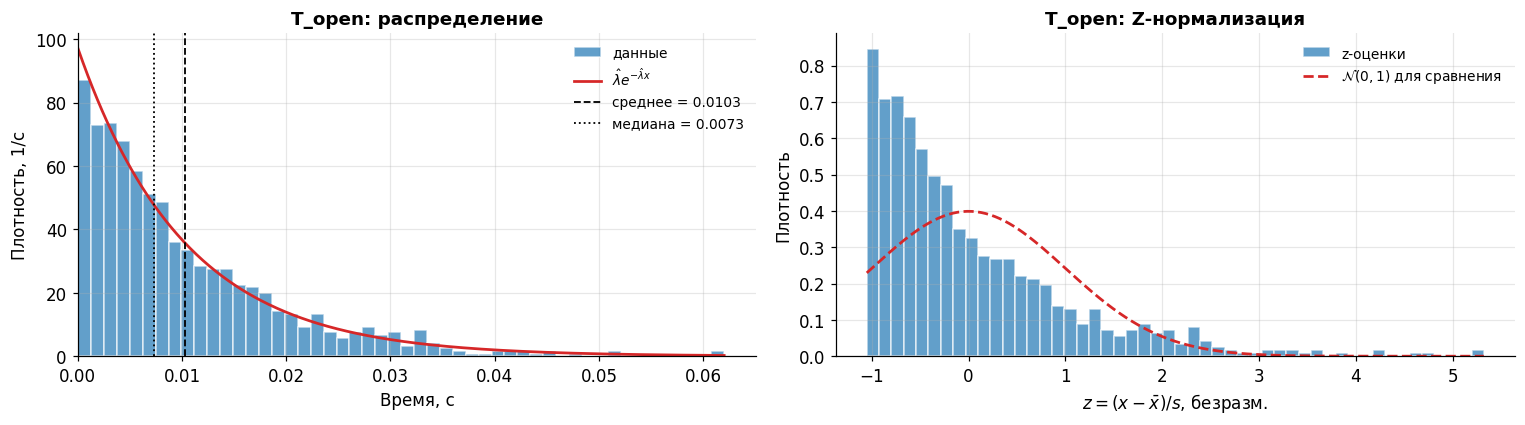

In [5]:
#@title EDA: T_open
x = open_dwell
print(f"T_open: n = {len(x)}, среднее = {x.mean():.4f} с, медиана = {np.median(x):.4f} с, s = {x.std():.4f} с")
open_dwell_norm = eda_plot(x, "T_open", COLORS["open"], "Время, с", "1/с", fit="expon")

**Вывод:** Гистограмма имеет падающий вид (экспоненциальный спад), ассиметрия положительна, что подтверждает случайную природу величины. Значения нельзя вычислить детерминированной формулой.

<a id="s2-3" name="s2-3"></a>
### 2.3 Доказательство случайности

Покажем, что значения $T_{open}$ нельзя вычислить детерминированной формулой:
1. **Разброс при одинаковых условиях.** Все интервалы — один канал при одних условиях. Для детерминированного процесса $CV = s/\bar x = 0$, у экспоненты $CV = 1$.
2. **Непредсказуемость по прошлому.** Если бы значение зависело от предыдущих, автокорреляции $\rho_k$ выходили бы за коридор шума $\pm 1.96/\sqrt n$.
3. **Критерий серий Вальда — Вольфовица.** Отмечаем значения выше/ниже медианы. Для случайного порядка число серий $R$ асимптотически нормально:
$$\mathbb E R = \frac{2n_1n_2}{n} + 1, \qquad \mathbb D R = \frac{2n_1n_2(2n_1n_2 - n)}{n^2(n-1)}.$$
Слишком мало серий — тренд, слишком много — периодичность. $H_0$: порядок случаен.

<sub>✏️ Раздел добавлен КТвД — см. [журнал правок](#s17), пункт А1.</sub>

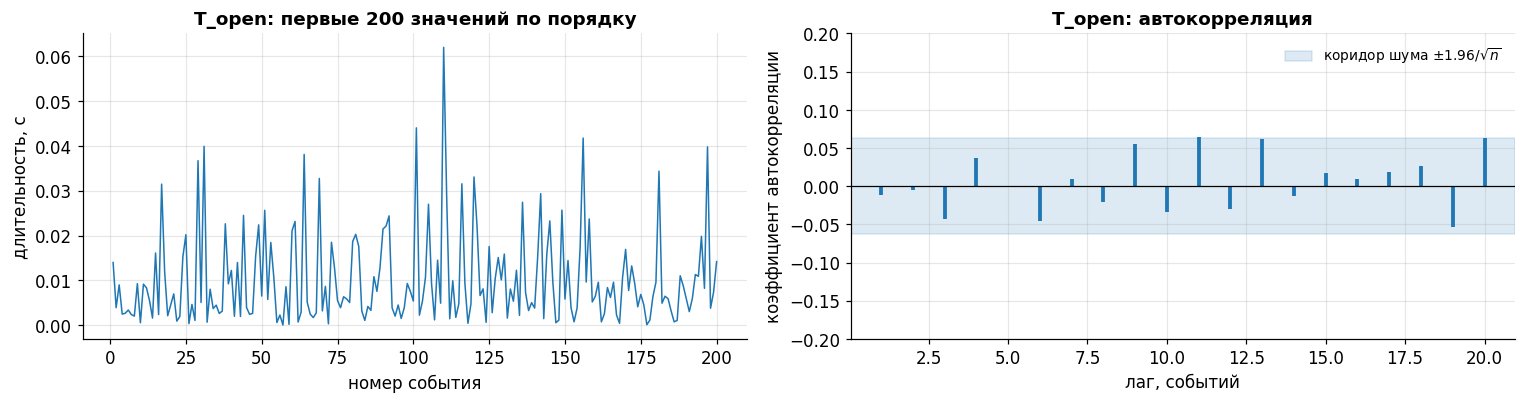

,значение
коэффициент вариации s / x̄ (у экспоненты 1),0.9474
лагов вне коридора (из 20),1.0000
число серий R,476.0000
ожидаемое число серий E[R],482.0000
p-значение критерия серий,0.6987


In [6]:
#@title Доказательство случайности: T_open
rand_open = randomness_report(open_dwell, "T_open", COLORS["open"])

**Вывод.** Если бы время открытия задавалось формулой, то при одних и тех же условиях все интервалы были бы одинаковыми и разброс был бы нулевым. У нас всё наоборот: стандартное отклонение почти равно среднему ($CV \approx 0.95$), ровно как и положено экспоненте. На графике первых 200 значений короткие и длинные интервалы идут вперемешку, никакой закономерности не видно. Автокорреляция это подтверждает: из 20 лагов за коридор шума вышел один, а при уровне 5 % один такой выход и ожидается чисто случайно. Критерий серий тоже не нашёл ни тренда, ни периодичности ($p \approx 0.70$).

Получается, что закон распределения $T_{open}$ мы описать можем, а предсказать конкретное значение — нет. Это и значит, что $T_{open}$ — случайная величина.


<a id="s2-4" name="s2-4"></a>
### 2.4 Состоятельность оценок

Оценка $\hat\theta_n$ состоятельна, если $\hat\theta_n \xrightarrow{P} \theta$ при $n\to\infty$. Для каждого $n$ берём 30 подвыборок без возвращения; линия — среднее оценок, полоса — их разброс. Сужение полосы с ростом $n$ — эмпирический признак состоятельности.

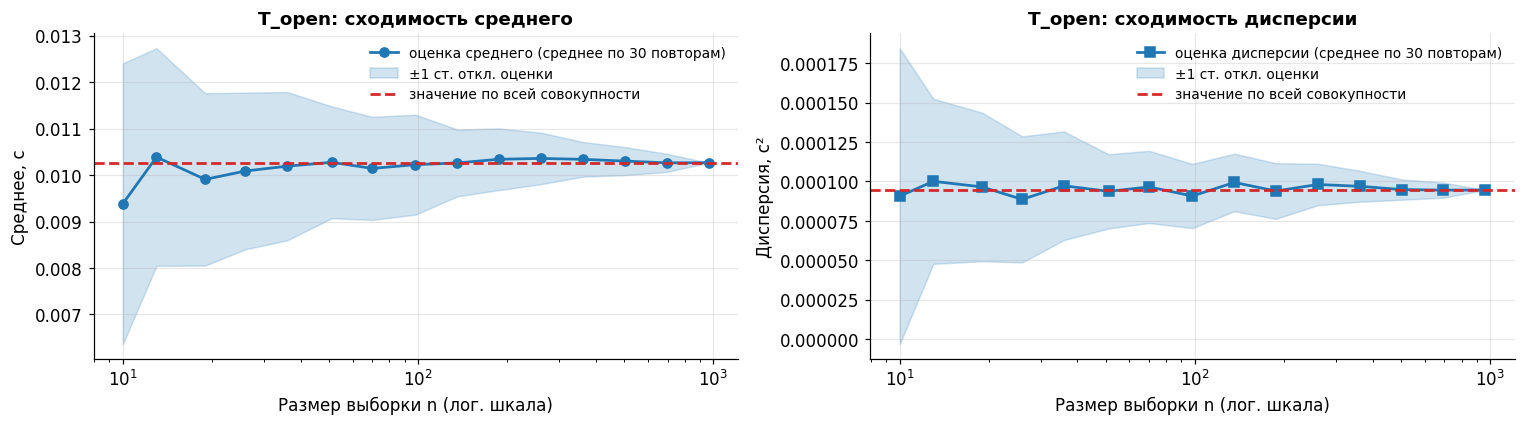

In [7]:
#@title Состоятельность оценок: T_open
consistency_plot(open_dwell, "T_open", COLORS["open"], "с")

**Вывод по состоятельности:** Проверка состоятельности проводилась с использованием случайных подвыборок (30 итераций для каждого размера, без возвращения). Построены графики сходимости как для выборочного среднего, так и для выборочной дисперсии. Оба графика демонстрируют приближение значений к истинным значениям при увеличении размера выборки, что подтверждает состоятельность оценок.

[↑ к содержанию](#toc)

<a id="s3" name="s3"></a>
## 3. Случайная величина 2: время в закрытом состоянии $T_{closed}$

<a id="s3-1" name="s3-1"></a>
### 3.1 Описание (природа события)

Время, в течение которого канал находится в закрытом состоянии, также является случайной величиной, зависящей от вероятности спонтанного открытия или закрытия. В двухсостояниевой модели оно подчиняется экспоненциальному закону.

<a id="s3-2" name="s3-2"></a>
### 3.2 Разведочный анализ и распределение

T_closed: n = 964, среднее = 0.0105 с, медиана = 0.0075 с, s = 0.0105 с


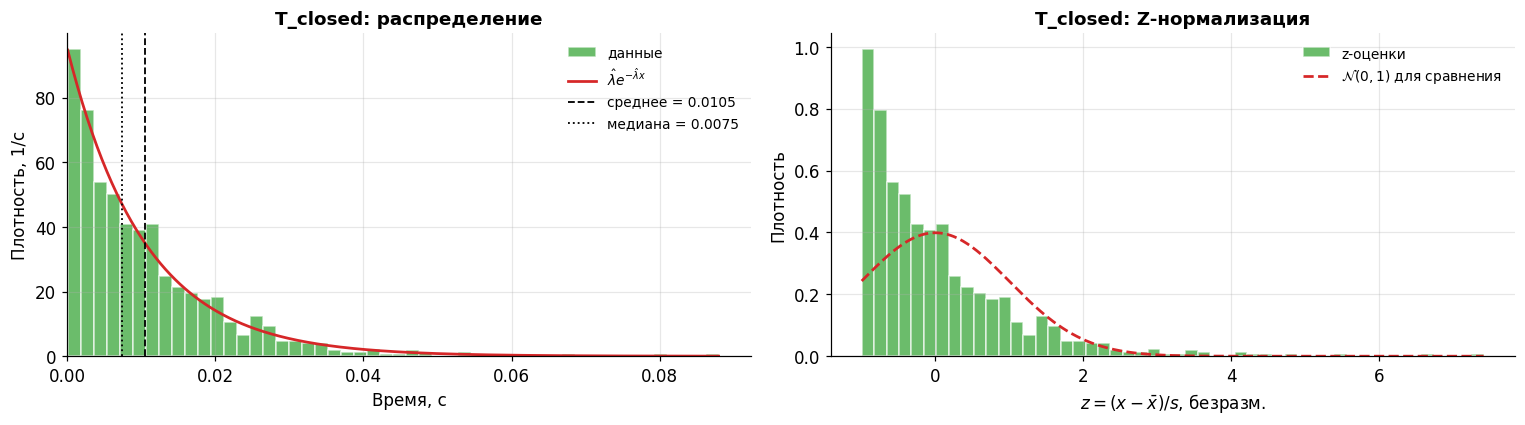

In [8]:
#@title EDA: T_closed
x = closed_dwell
print(f"T_closed: n = {len(x)}, среднее = {x.mean():.4f} с, медиана = {np.median(x):.4f} с, s = {x.std():.4f} с")
closed_dwell_norm = eda_plot(x, "T_closed", COLORS["closed"], "Время, с", "1/с", fit="expon")

**Вывод:** Распределение также имеет падающий вид.

<a id="s3-3" name="s3-3"></a>
### 3.3 Доказательство случайности

Покажем, что значения $T_{closed}$ нельзя вычислить детерминированной формулой:
1. **Разброс при одинаковых условиях.** Все интервалы — один канал при одних условиях. Для детерминированного процесса $CV = s/\bar x = 0$, у экспоненты $CV = 1$.
2. **Непредсказуемость по прошлому.** Если бы значение зависело от предыдущих, автокорреляции $\rho_k$ выходили бы за коридор шума $\pm 1.96/\sqrt n$.
3. **Критерий серий Вальда — Вольфовица.** Отмечаем значения выше/ниже медианы. Для случайного порядка число серий $R$ асимптотически нормально:
$$\mathbb E R = \frac{2n_1n_2}{n} + 1, \qquad \mathbb D R = \frac{2n_1n_2(2n_1n_2 - n)}{n^2(n-1)}.$$
Слишком мало серий — тренд, слишком много — периодичность. $H_0$: порядок случаен.

<sub>✏️ Раздел добавлен КТвД — см. [журнал правок](#s17), пункт А1.</sub>

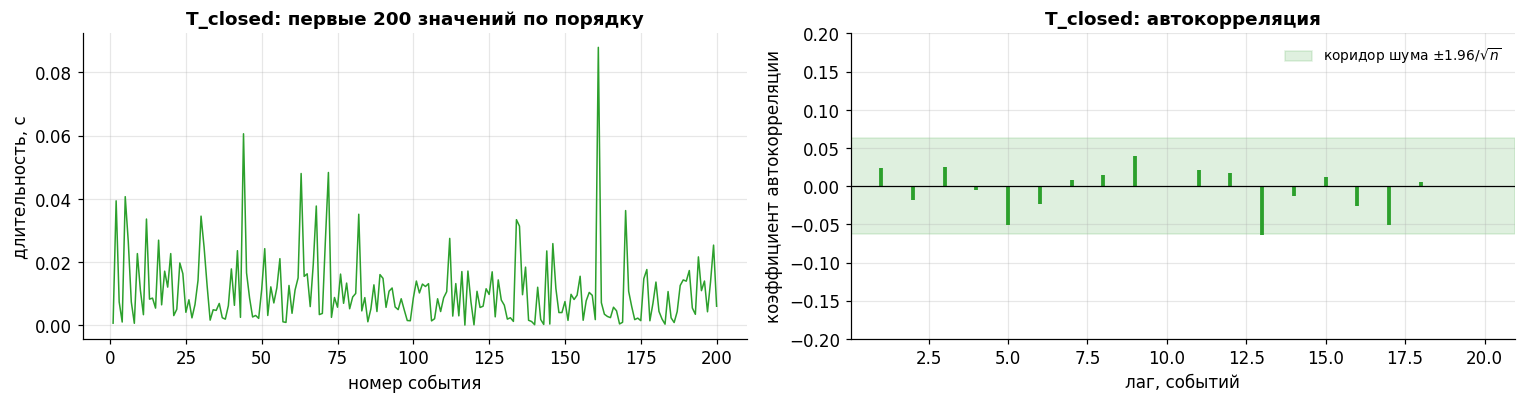

,значение
коэффициент вариации s / x̄ (у экспоненты 1),0.9976
лагов вне коридора (из 20),1.0000
число серий R,473.0000
ожидаемое число серий E[R],483.0000
p-значение критерия серий,0.5193


In [9]:
#@title Доказательство случайности: T_closed
rand_closed = randomness_report(closed_dwell, "T_closed", COLORS["closed"])

**Вывод.** С закрытым состоянием картина та же. Разброс огромный, стандартное отклонение равно среднему ($CV \approx 1.00$), значения скачут без всякого порядка. За коридор шума вышел один лаг из 20 (столько и ожидается случайно), критерий серий порядок не отвергает ($p \approx 0.52$). Значит, $T_{closed}$ тоже нельзя посчитать по формуле — это случайная величина.


<a id="s3-4" name="s3-4"></a>
### 3.4 Состоятельность оценок

Оценка $\hat\theta_n$ состоятельна, если $\hat\theta_n \xrightarrow{P} \theta$ при $n\to\infty$. Для каждого $n$ берём 30 подвыборок без возвращения; линия — среднее оценок, полоса — их разброс. Сужение полосы с ростом $n$ — эмпирический признак состоятельности.

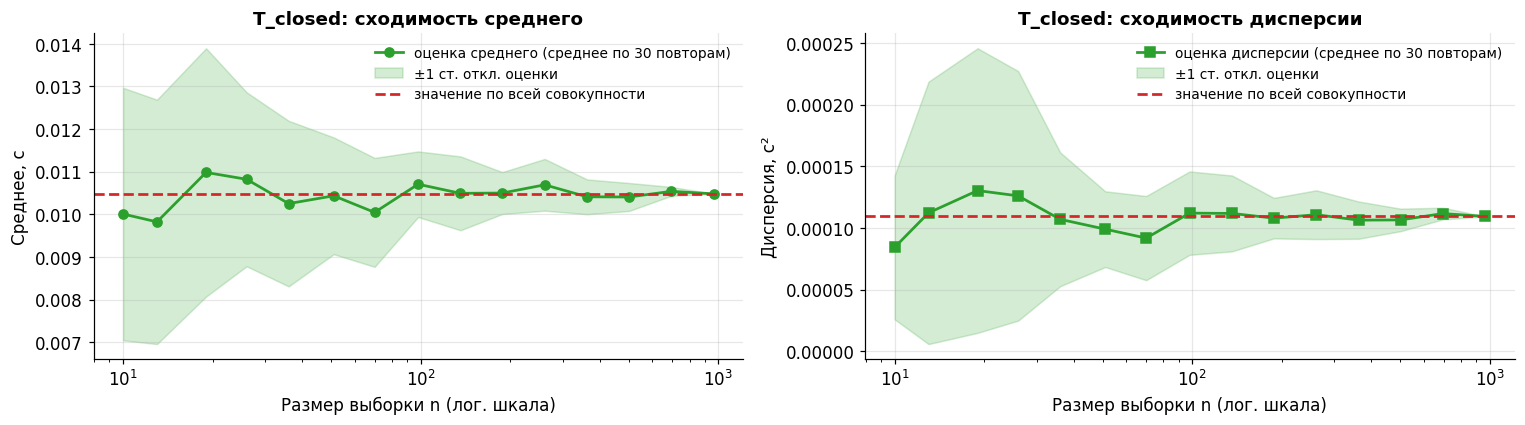

In [10]:
#@title Состоятельность оценок: T_closed
consistency_plot(closed_dwell, "T_closed", COLORS["closed"], "с")

**Вывод по состоятельности:** Использованы случайные подвыборки без возвращения (30 итераций). Графики показывают, что при увеличении размера выборки и выборочное среднее, и выборочная дисперсия стабилизируются около истинных значений, что подтверждает их состоятельность.

[↑ к содержанию](#toc)

<a id="s4" name="s4"></a>
## 4. Независимость $T_{open}$ и $T_{closed}$

$T_{open}$ и $T_{closed}$ описывают одно событие (переходы канала между состояниями), поэтому проверяем их независимость на парах соседних интервалов $(T_{open}^{(i)}, T_{closed}^{(i)})$.

- $H_0$: величины независимы. $H_1$: между ними есть связь.
- Критерии: корреляция Пирсона (линейная связь), Спирмена (монотонная связь), $\chi^2$ по таблице сопряжённости $2\times2$ (выше/ниже медианы).
- Уровень значимости $\alpha = 0.05$.

In [11]:
#@title Корреляции Пирсона, Спирмена и критерий χ²
print("Проверка независимости (открытое и закрытое состояния)")

# 1. Естественное сравнение: соседние пары (открыт -> закрыт)
# Канал всегда чередует состояния, поэтому берем пары подряд
min_len = min(len(open_dwell), len(closed_dwell))
pairs_open = open_dwell[:min_len]
pairs_closed = closed_dwell[:min_len]

# 2. Корреляция Пирсона
corr_p, p_p = stats.pearsonr(pairs_open, pairs_closed)
print(f"Пирсон: r={corr_p:.4f}, p-значение={p_p:.4e}")

# 3. Корреляция Спирмена
corr_s, p_s = spearmanr(pairs_open, pairs_closed)
print(f"Спирмен: r={corr_s:.4f}, p-значение={p_s:.4e}")

# 4. Хи-квадрат по таблице сопряженности
# Берем медианы как порог
median_open = np.median(pairs_open)
median_closed = np.median(pairs_closed)

contingency_table = pd.crosstab(
    pairs_open > median_open,
    pairs_closed > median_closed
)
chi2, p_chi2, dof, expected = chi2_contingency(contingency_table)
print(f"Хи-квадрат: χ²={chi2:.4f}, p-значение={p_chi2:.4e}")

if p_p > 0.05 and p_s > 0.05 and p_chi2 > 0.05:
    print("Вывод: во всех тестах p > 0.05, оснований отвергнуть независимость нет.")
else:
    print("Вывод: Есть основания полагать, что величины зависимы (p < 0.05 хотя бы в одном тесте).")

Проверка независимости (открытое и закрытое состояния)
Пирсон: r=0.0004, p-значение=9.9115e-01
Спирмен: r=0.0138, p-значение=6.6918e-01
Хи-квадрат: χ²=2.0083, p-значение=1.5644e-01
Вывод: во всех тестах p > 0.05, оснований отвергнуть независимость нет.


**Вывод.** Связи между длительностью открытого состояния и соседнего закрытого мы не нашли. Линейной связи нет (Пирсон, $r = 0.0004$), монотонной тоже (Спирмен, $r = 0.014$), и таблица «длинный / короткий интервал» ничего не показала ($\chi^2 = 2.01$, $p = 0.16$). Все $p$ больше 0.05, так что отвергать гипотезу о независимости нам нечем.

Это хорошо сходится с моделью: канал «не помнит», сколько он только что был открыт, когда «решает», сколько пробыть закрытым.


[↑ к содержанию](#toc)

<a id="s5" name="s5"></a>
## 5. Случайная величина 3: амплитуда тока $I_{open}$

<a id="s5-1" name="s5-1"></a>
### 5.1 Описание (природа события)

Амплитуда тока, протекающего через открытый канал, не является строго постоянной из-за теплового шума и флуктуаций ионных потоков. Это случайная величина, которая, согласно центральной предельной теореме, должна подчиняться нормальному распределению.

<a id="s5-2" name="s5-2"></a>
### 5.2 Разведочный анализ и распределение

I_open: n = 247412, среднее = 17.5676 пА, медиана = 17.5673 пА, s = 1.7335 пА


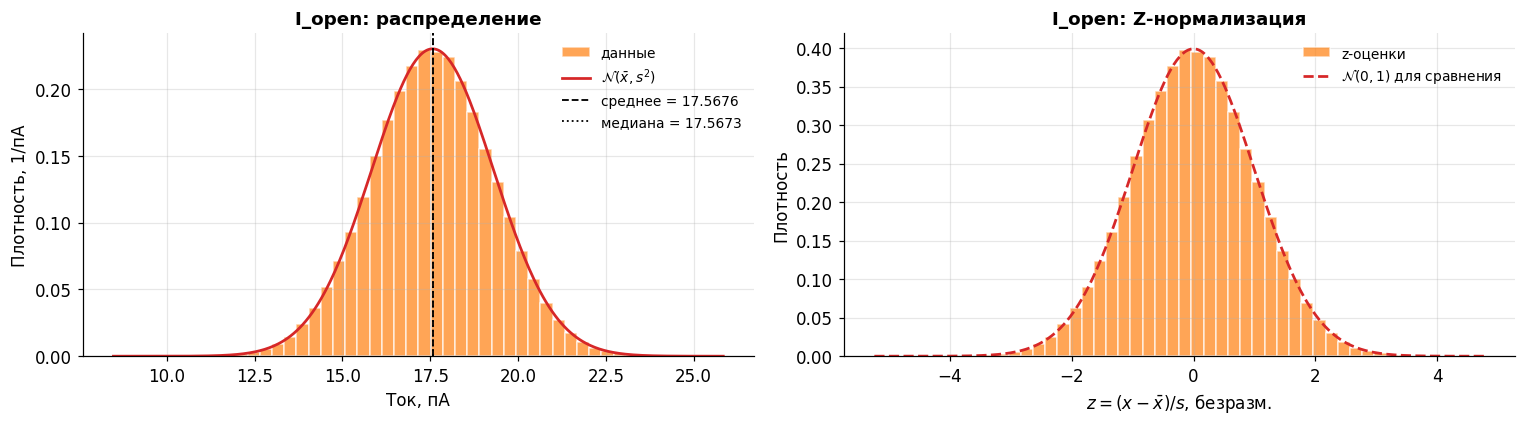

,доля в данных,теория 2(1 − Φ(k))
|Z| > 1,0.31737,0.31731
|Z| > 2,0.04514,0.04550
|Z| > 3,0.00286,0.00270


In [12]:
#@title Статистики, гистограмма и Z-нормализация $I_{open}$
x = current_open
print(f"I_open: n = {len(x)}, среднее = {x.mean():.4f} пА, медиана = {np.median(x):.4f} пА, s = {x.std(ddof=1):.4f} пА")
current_norm = eda_plot(x, "I_open", COLORS["current"], "Ток, пА", "1/пА", fit="norm")

# проверка правила 1–2–3σ после стандартизации
rule = pd.DataFrame({"доля в данных": [np.mean(np.abs(current_norm) > k) for k in (1, 2, 3)],
                     "теория 2(1 − Φ(k))": [2 * stats.norm.sf(k) for k in (1, 2, 3)]},
                    index=["|Z| > 1", "|Z| > 2", "|Z| > 3"])
display(rule.round(5))

> ✏️ **Правка КТвД № 2.** Графики тока были в своём стиле (цвета вручную, чёрные края, ось без подписи и единиц). Переведены на общую функцию `eda_plot`; добавлена проверка правила 1–2–3σ. Подробно — [журнал правок](#s17).

**Z-нормализация.** Так как $I_{open}$ близка к нормальной, приводим её к стандартной нормальной:
$$Z = \frac{I - \bar I}{s}, \qquad Z \sim \mathcal N(0, 1).$$
Мотивация: величина становится безразмерной, её можно сравнивать с табличными квантилями $\mathcal N(0,1)$ и с другими величинами в одной шкале, а правило $|Z| > 3$ сразу выделяет выбросы.

In [13]:
#@title Критерий Шапиро–Уилка на подвыборке n = 5000
print("Тест Шапиро-Уилка для тока (СВ 3)")
np.random.seed(42)
sample_current = np.random.choice(current_open, size=5000, replace=False)
stat, p = shapiro(sample_current)
print(f"p-значение = {p:.4e}")
if p > 0.05:
    print("Вывод: нормальность не отвергается.")
else:
    print("Вывод: нормальность отвергается (p < 0.05).")

Тест Шапиро-Уилка для тока (СВ 3)
p-значение = 6.0969e-02
Вывод: нормальность не отвергается.


Один запуск Шапиро — Уилка на $n = 5000$ даёт $p$ около границы $0.05$, и на другой подвыборке результат может перевернуться. Поэтому проверяем на **200 подвыборках**: если $H_0$ верна, p-значение распределено равномерно на $(0,1)$ и доля $p < 0.05$ должна быть около $5\,\%$.

,медиана p,доля p < 0.05,ожидается при H0
Шапиро — Уилк,0.554,0.065,0.05
Д'Агостино — Пирсон,0.503,0.040,0.05


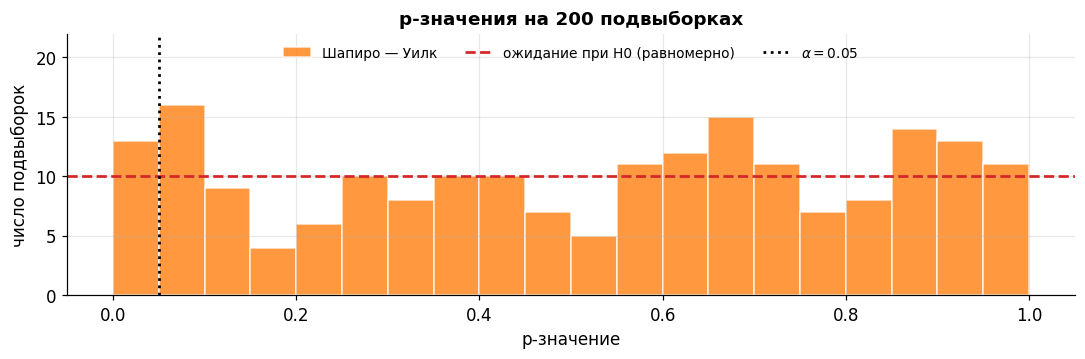

In [14]:
#@title Шапиро — Уилк на 200 подвыборках
rng_sw = np.random.default_rng(7)
p_sw = np.array([shapiro(rng_sw.choice(current_open, 5000, replace=False)).pvalue for _ in range(200)])
p_da = np.array([stats.normaltest(rng_sw.choice(current_open, 5000, replace=False)).pvalue for _ in range(200)])
display(pd.DataFrame({"медиана p": [np.median(p_sw), np.median(p_da)],
                      "доля p < 0.05": [np.mean(p_sw < .05), np.mean(p_da < .05)],
                      "ожидается при H0": [.05, .05]},
                     index=["Шапиро — Уилк", "Д'Агостино — Пирсон"]).round(3))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(p_sw, bins=np.linspace(0, 1, 21), color=COLORS["current"], alpha=.8, edgecolor="white", label="Шапиро — Уилк")
ax.axhline(10, color=COLORS["theory"], ls="--", label="ожидание при H0 (равномерно)")
ax.axvline(.05, color="k", ls=":", label=r"$\alpha = 0.05$")
ax.set_ylim(0, 22)
decorate(ax, "p-значения на 200 подвыборках", "p-значение", "число подвыборок"); ax.legend(ncol=3, loc="upper center"); plt.tight_layout(); plt.show()

> ✏️ **Правка КТвД № 3.** Один запуск Шапиро — Уилка давал $p \approx 0.06$ у самой границы, и вывод зависел от случайной подвыборки. Добавлена проверка на 200 подвыборках. Подробно — [журнал правок](#s17).

**Вывод:** Гистограмма имеет вид «колокола».
Тест Шапиро-Уилка на подвыборке из 5000 значений показал p-значение > 0.05, что подтверждает гипотезу о нормальности. Тест очень чувствительный: на разных случайных подвыборках p-значение может колебаться около границы 0.05, что связано с дискретностью данных и наличием шума. Однако визуально распределение имеет ярко выраженный вид «колокола», характерный для нормального закона.

<a id="s5-3" name="s5-3"></a>
### 5.3 Состоятельность оценок

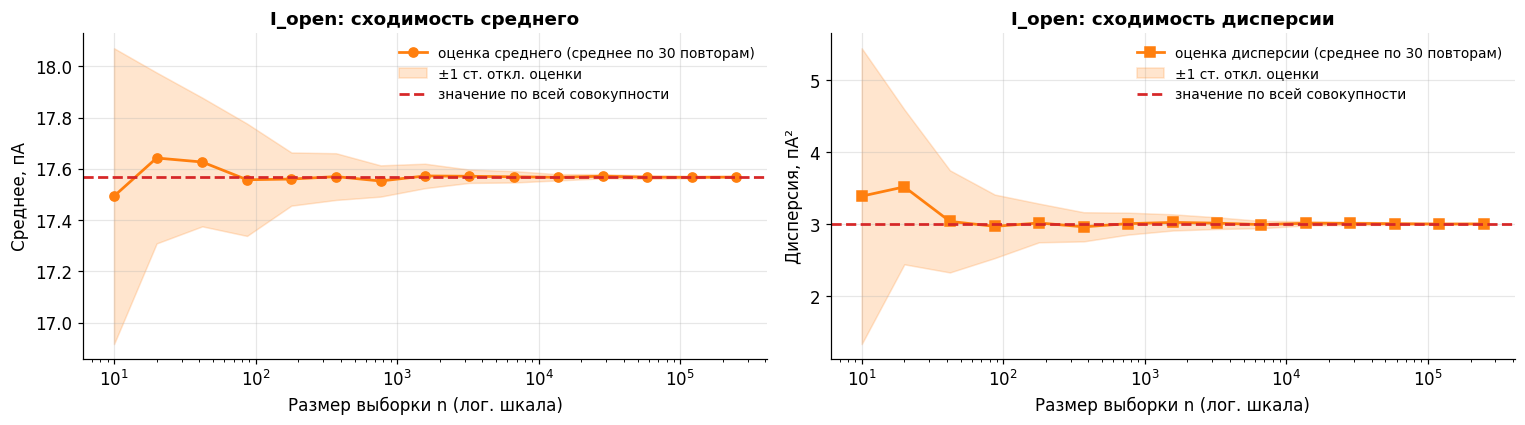

In [15]:
#@title Сходимость среднего и дисперсии $I_{open}$
consistency_plot(current_open, "I_open", COLORS["current"], "пА")

> ✏️ **Правка КТвД № 4.** График сходимости тока был в своём стиле; переведён на общую функцию `consistency_plot`. Подробно — [журнал правок](#s17).

**Вывод по состоятельности:** Благодаря большому объему данных (около 250 000 значений), оценки среднего и дисперсии сходятся к истинным значениям очень быстро. Это подтверждает состоятельность оценок для данной случайной величины.

[↑ к содержанию](#toc)

<a id="s6" name="s6"></a>
## 6. Генеральная совокупность и выборка

Наша генеральная совокупность состоит почти из 1000 значений, поэтому для нашего анализа мы берем выборку 100 значений (это  почти 10% от всей совокупности). Это оптимальный размер, поскольку 100 значений достаточно, чтобы выборка отражала свойства генеральной совокупности и чтобы мы смогли наглядно увидеть разницу между выборкой и изначальными параметрами.

Далее мы сравниваем статистики (среднее, дисперсию, медиану) для трех случаев: генеральная совокупность, выборка с возвращением и выборка без возвращения.

Для выборки без возвращения дисперсия выборочного среднего содержит поправку на конечную совокупность:
$$D(\bar x) = \frac{\sigma^2}{n}\cdot\frac{N-n}{N-1} \quad\text{(без возвращения)}, \qquad D(\bar x) = \frac{\sigma^2}{n} \quad\text{(с возвращением)}.$$

In [16]:
#@title Статистики: генеральная совокупность и две выборки
from IPython.display import display
rng = np.random.default_rng(2026)
all_data = open_dwell #наша генеральная совокупность
N = len(all_data)
n = 100

sample_bez = rng.choice(all_data, size=n, replace=False) #выборка без возвращений
sample_s = rng.choice(all_data, size=n, replace=True) #очевидно что с возвращениями:)

df_stats = pd.DataFrame({
    'Генеральная': [N, all_data.mean(), all_data.var(ddof=0), np.median(all_data)],
    'Выборка без возвращений': [n, sample_bez.mean(), sample_bez.var(ddof=1), np.median(sample_bez)],
    'Выборка с возвращениями': [n, sample_s.mean(), sample_s.var(ddof=1), np.median(sample_s)]}
, index = ['Размер', 'Среднее', 'Дисперсия', 'Медиана'])
display(df_stats.style.format('{:.4g}').set_caption('Время — в секундах, дисперсия — в с²'))

,Генеральная,Выборка без возвращений,Выборка с возвращениями
Размер,964,100,100
Среднее,0.01027,0.01157,0.009859
Дисперсия,9.45e-05,0.0001127,0.0001068
Медиана,0.00728,0.0083,0.00562


> ✏️ **Правка КТвД № 5.** Таблица округлялась до 6 знаков, и дисперсия выводилась как `0.000095`. Теперь 4 значащие цифры. Подробно — [журнал правок](#s17).

In [17]:
#@title 5000 повторов: смещение и дисперсия выборочного среднего
#одна выборка может случайно дать искаженный вариант или нет, поэтому повторяем выбор много раз
B = 5000
means_wo = np.array([rng.choice(all_data, n, replace=False).mean() for _ in range(B)])
means_w = np.array([rng.choice(all_data, n, replace=True).mean()  for _ in range(B)])
sigma2 = all_data.var(ddof=0)
fpc = (N - n) / (N - 1)

res = pd.DataFrame({
    'Без возвращений': [means_wo.mean() - all_data.mean(), means_wo.var(ddof=1), sigma2/n*fpc],
    'С возвращениями': [means_w.mean() - all_data.mean(),  means_w.var(ddof=1),  sigma2/n]
}, index=['Смещение среднего', 'Дисперсия выборочного среднего (эмпирически)', 'Дисперсия среднего (теория)'])
display(res)
print(f"Поправка на конечную совокупность (N-n)/(N-1) = {fpc:.4f}")

,Без возвращений,С возвращениями
Смещение среднего,-1.013033e-05,4.180949e-06
Дисперсия выборочного среднего (эмпирически),8.392894e-07,9.612560e-07
Дисперсия среднего (теория),8.478640e-07,9.450151e-07


Поправка на конечную совокупность (N-n)/(N-1) = 0.8972


**Вывод:** обе выборки по среднему, дисперсии и медиане близки к генеральной совокупности, расхождения объясняются случайностью выбора (одна выборка из 100 значений даёт лишь один случайный результат). При многократном повторении видно главное различие подходов: среднее несмещено в обоих случаях, но выборка **без возвращений** даёт меньшую дисперсию среднего против у выборки с возвращениями. Здесь множитель равен ≈ 0.90, то есть без возвращений оценка среднего точнее, потому что каждый элемент попадает в выборку не более одного раза.

[↑ к содержанию](#toc)

<a id="s7" name="s7"></a>
## 7. Математическая база распределения

Для описания времени жизни ионного канала в биофизике традиционно используется **экспоненциальное распределение**.

**Ионный канал** - это сложная белковая молекула. Его открытие и закрытие происходит из-за случайных тепловых флуктуаций (броуновского движения), молекулы воды постоянно сталкиваются с молекулой белка. Чтобы канал сменил состояние, молекула должна преодолеть энергетический барьер. Вероятность преодолеть этот барьер за единицу времени постоянна, что в физике идеально описывается пуассоновским потоком событий, а время между событиями в таком потоке подчиняется экспоненциальному распределению.

**Интересный факт:**

У настоящего ChR2 (светочувствительного канала, который встраивают в нейроны мышей) открытие запускает свет: фотон вызывает изомеризацию ретиналя, и канал открывается. А вот закрывается он уже сам, за счёт тепловых флуктуаций, поэтому в опытах с ChR2 время жизни открытого состояния случайно, даже когда момент вспышки известен точно.

В нашей модели света нет вообще: канал и открывается, и закрывается спонтанно, с постоянными интенсивностями $k_1 = k_2 = 100\ \text{с}^{-1}$. Поэтому экспоненциальный закон мы ожидаем для обеих величин — и для $T_{open}$, и для $T_{closed}$.

<sub>✏️ Правка КТвД № 12 — см. [журнал правок](#s17).</sub>

Чтобы описать эту случайность математически, мы используем формулы экспоненциального закона:

**Плотность вероятности:**
$$ f(x) = \lambda e^{-\lambda x}, \quad x \ge 0 $$

**Функция распределения:**
$$ F(x) = 1 - e^{-\lambda x}, \quad x \ge 0 $$

**Математическое ожидание:**
$$ \mathbb{E}(X) = \frac{1}{\lambda} $$

**Дисперсия:**
$$ \mathbb{D}(X) = \frac{1}{\lambda^2} $$

*(где $\lambda > 0$ — интенсивность переходов канала из одного состояния в другое).*

Свойства распределения:

Экспоненциальное распределение моделирует время между событиями. Оно обладает уникальным свойством «отсутствия памяти». Это значит, что вероятность того, что канал закроется или откроется в следующую секунду, абсолютно не зависит от того, сколько времени он уже находится в текущем состоянии. Канал «не стареет» и не «помнит» свое прошлое.

[↑ к содержанию](#toc)

<a id="s8" name="s8"></a>
## 8. Проверка гипотезы

В опытах с ChR2 исследователям крайне важно знать, как долго белок остается открытым после вспышки света. От этого зависит, сколько ионов пройдет в нейрон и возникнет ли нервный импульс. Мы предполагаем, что закрытие канала - это процесс без памяти, а значит, время его жизни подчиняется экспоненте.

**Наши гипотезы:**
*   **Основная гипотеза:** Время жизни канала в открытом состоянии подчиняется экспоненциальному распределению (процесс случайный и не имеет памяти).
*   **Альтернативная гипотеза:** Распределение отличается от экспоненциального (например, в кинетике белка есть скрытые состояния).

**Для проверки будем использовать критерий Колмогорова — Смирнова (дальше — КС)**

Критерий Колмогорова-Смирнова - это непараметрический тест. Он не разбивает данные на интервалы, а сравнивает две интегральные кривые (функции распределения):
1. Эмпирическую (построенную по нашим точкам)
2. Теоретическую (идеальную экспоненту)

Тест ищет **максимальное вертикальное расстояние** между этими двумя кривыми. Чем ближе эмпирическая кривая прижимается к теоретической, тем меньше и тем выше шанс, что наши данные действительно экспоненциальны. Если p-значение > 0.05, мы принимаем гипотезу.

**Еще один интересный факт из биофизики:**
В нашем датасете используется упрощенная двухсостояниевая модель (открыт/закрыт), поэтому данные идеально ложатся на экспоненту. В реальных же экспериментах белок ChR2 намного сложнее! У него есть несколько промежуточных состояний. Поэтому реальные графики ученых часто описываются суммой нескольких экспонент. Понимание этой кинетики позволяет биофизикам точно рассчитывать частоту вспышек света, чтобы нейрон не «сгорел» от переизбытка ионов при слишком частой стимуляции.

Статистика критерия Колмогорова–Смирнова:
$$D_n = \sup_x \left| F_n(x) - F(x) \right|, \qquad F(x) = 1 - e^{-\hat\lambda x}, \quad \hat\lambda = 1/\bar x.$$

In [18]:
#@title Критерий Колмогорова–Смирнова для $T_{open}$
#находим среднее время, чтобы вычислить интенсивность
lambda_est = 1 / all_data.mean()
scale_est = 1 / lambda_est

#проводим KS-тест
stat, p_value = kstest(all_data, 'expon', args=(0, scale_est))

print(f"Статистика критерия (D): {stat:.4f}")
print(f"p-значение: {p_value:.4f}\n")

alpha = 0.05
if p_value > alpha:
    print("Вывод: гипотеза не отвергается (p-значение > 0.05).")
    print("Данные согласуются с экспоненциальным распределением.")
else:
    print("Вывод: гипотеза отвергается (p-значение < 0.05).")
    print("Данные не согласуются с экспоненциальным распределением.")

Статистика критерия (D): 0.0255
p-значение: 0.5509

Вывод: гипотеза не отвергается (p-значение > 0.05).
Данные согласуются с экспоненциальным распределением.


Проверка показала, что $p = 0.55 > 0.05$. Это означает, что разница между нашими реальными данными и теоретической
экспоненциальной кривой статистически незначима.

Следовательно, наша гипотеза о том, что время жизни канала подчиняется экспоненте, **не отвергается**. Это согласуется с природой процесса: после того как свет погас, белок ChR2 закрывается исключительно из-за случайного теплового движения молекул, а не по какому-то внутреннему таймеру.

> ✏️ **Правка КТвД № 6.** Было «гипотеза подтвердилась», стало «не отвергается»: статистический критерий не доказывает $H_0$, а только не находит оснований её отвергнуть. Подробно — [журнал правок](#s17).

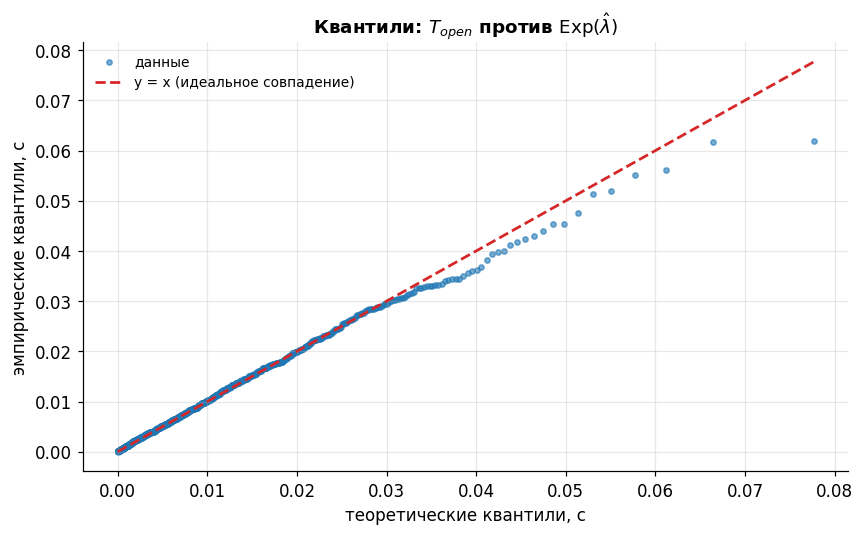

In [19]:
#@title График квантилей: эмпирические и теоретические
lam = 1 / all_data.mean()
y = np.sort(all_data)
p = (np.arange(1, len(y) + 1) - 0.5) / len(y)        # позиции Хазена: без искусственного «загиба» хвоста
x = -np.log(1 - p) / lam
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color=COLORS["open"], s=12, alpha=.6, label="данные")
ax.plot([0, x.max()], [0, x.max()], color=COLORS["theory"], ls="--", label="y = x (идеальное совпадение)")
decorate(ax, r"Квантили: $T_{open}$ против $\mathrm{Exp}(\hat\lambda)$", "теоретические квантили, с", "эмпирические квантили, с")
plt.tight_layout(); plt.show()

---
✏️ **Правка КТвД № 7 — формула уровней квантилей на график квантилейе.**

Теоретический квантиль экспоненты для $i$-й по величине точки: $x_i = -\ln(1 - p_i)/\hat\lambda$, где $p_i$ — доля данных ниже этой точки.

| | формула $p_i$ | уровень последней точки ($n = 964$) | её теоретический квантиль |
|---|---|---|---|
| было | `np.linspace(0.01, 0.99, n)`, то есть $p_i = 0.01 + 0.98\,\frac{i-1}{n-1}$ | $0.99$ | $4.6/\hat\lambda \approx 0.047$ с |
| стало | $p_i = \dfrac{i - 0.5}{n}$ (позиции Хазена) | $0.9995$ | $7.6/\hat\lambda \approx 0.078$ с |

**Почему.** В старой формуле крайние точки получали неверные уровни: самые длинные интервалы сравнивались с квантилем почти вдвое меньше нужного и поднимались над линией $y = x$. Хвост ложно «загибался», как будто экспонента плохо описывает данные. С правильными уровнями точки лежат на линии до конца. Подробно — [журнал правок](#s17).

---

График наглядно показывает, что время жизни канала ChR2 - это настоящий случайный процесс, который подчиняется экспоненциальному распределению.

<a id="s8-1" name="s8-1"></a>
### 8.1 Дополнительные гипотезы

| № | $H_0$ | $H_1$ | критерий |
|---|---|---|---|
| H2 | $T_{open} \sim \mathrm{Exp}$ с учётом того, что $\hat\lambda$ оценён по тем же данным | распределение другое | КС с поправкой Лиллиефорса (параметрический бутстрэп) |
| H3 | $\lambda = 100\ \text{с}^{-1}$ (значение, заложенное в симуляцию: `k1 = 100`) | $\lambda \ne 100$ | точный критерий: $2\lambda_0\sum t_i \sim \chi^2(2n)$ |
| H4 | нет памяти: $(T - s \mid T > s) \overset{d}{=} T$ | память есть | двухвыборочный критерий КС |
| H5 | $T_{closed} \sim \mathrm{Exp}$ | распределение другое | КС с поправкой Лиллиефорса |

**Почему нужна поправка Лиллиефорса.** Таблицы критерия КС верны, только если параметр известен заранее. Когда $\hat\lambda$ взят из тех же данных, теоретическая кривая «подогнана» к выборке, $D_n$ систематически меньше и p-значение завышено. Распределение $D_n$ при $H_0$ получаем симуляцией: генерируем выборки из экспоненты того же объёма, для каждой заново оцениваем $\lambda$ и считаем $D_n$ (Лиллиефорс, 1969).

**Точный критерий для $\lambda$.** Если $T_i \sim \mathrm{Exp}(\lambda)$ независимы, то $2\lambda T_i \sim \chi^2(2)$ и $2\lambda\sum_{i=1}^n T_i \sim \chi^2(2n)$. Отсюда статистика $2\lambda_0\sum t_i$ и точный доверительный интервал
$$\left[\frac{\chi^2_{\alpha/2}(2n)}{2\sum t_i};\ \frac{\chi^2_{1-\alpha/2}(2n)}{2\sum t_i}\right].$$

<sub>✏️ Раздел добавлен КТвД — см. [журнал правок](#s17), пункт А2.</sub>

,гипотеза H0,статистика,p-значение,решение (α = 0.05)
№,,,,
H1,"T_open ~ Exp, КС (раздел 8)",0.0255,0.5509,не отвергаем
H2,"T_open ~ Exp, КС + Лиллиефорс",0.0255,0.3103,не отвергаем
H3,"λ = 100 1/с, χ²(2n); ДИ 95 %: [91.4; 103.7] 1/с",1979.2960,0.4068,не отвергаем
H4,"нет памяти, s = медиана = 0.0073 с",0.0296,0.9303,не отвергаем
H5,"T_closed ~ Exp, КС + Лиллиефорс",0.0210,0.5982,не отвергаем


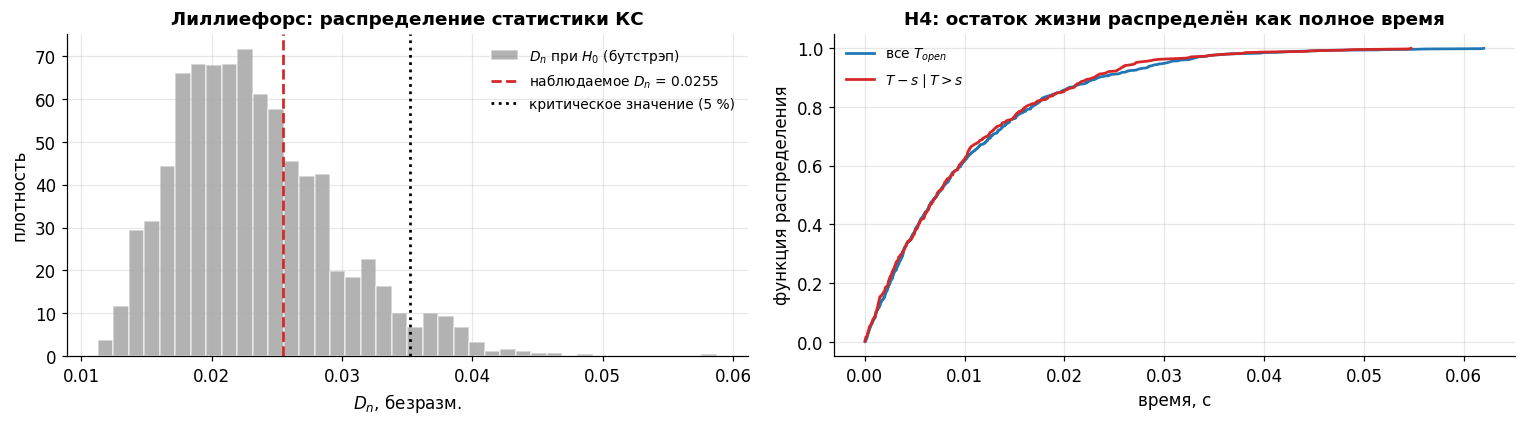

In [20]:
#@title Гипотезы H2–H5
def ks_lilliefors(x, B=2000, seed=0):
    x = np.asarray(x, float); rng_b = np.random.default_rng(seed)
    d_obs = kstest(x, "expon", args=(0, x.mean())).statistic
    d_b = np.array([kstest(y, "expon", args=(0, y.mean())).statistic
                    for y in (rng_b.exponential(1.0, len(x)) for _ in range(B))])
    return d_obs, (np.sum(d_b >= d_obs) + 1) / (B + 1), d_b

d2, p2, d_boot = ks_lilliefors(open_dwell)
n_o, s_o, lam0 = len(open_dwell), open_dwell.sum(), 100.0
T3 = 2 * lam0 * s_o; c3 = stats.chi2.cdf(T3, 2 * n_o); p3 = 2 * min(c3, 1 - c3)
ci = (stats.chi2.ppf(.025, 2 * n_o) / (2 * s_o), stats.chi2.ppf(.975, 2 * n_o) / (2 * s_o))
s_age = np.median(open_dwell); resid = open_dwell[open_dwell > s_age] - s_age
ks4 = stats.ks_2samp(resid, open_dwell)
d5, p5, _ = ks_lilliefors(closed_dwell, seed=1)

hyp = pd.DataFrame([
    ["H1", "T_open ~ Exp, КС (раздел 8)", stat, p_value],
    ["H2", "T_open ~ Exp, КС + Лиллиефорс", d2, p2],
    ["H3", f"λ = 100 1/с, χ²(2n); ДИ 95 %: [{ci[0]:.1f}; {ci[1]:.1f}] 1/с", T3, p3],
    ["H4", f"нет памяти, s = медиана = {s_age:.4f} с", ks4.statistic, ks4.pvalue],
    ["H5", "T_closed ~ Exp, КС + Лиллиефорс", d5, p5],
], columns=["№", "гипотеза H0", "статистика", "p-значение"]).set_index("№")
hyp["решение (α = 0.05)"] = np.where(hyp["p-значение"] > .05, "не отвергаем", "отвергаем")
display(hyp.style.format({"статистика": "{:.4f}", "p-значение": "{:.4f}"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(d_boot, bins=40, density=True, color=COLORS["real"], alpha=.6, edgecolor="white", label="$D_n$ при $H_0$ (бутстрэп)")
ax[0].axvline(d2, color=COLORS["theory"], ls="--", label=f"наблюдаемое $D_n$ = {d2:.4f}")
ax[0].axvline(np.quantile(d_boot, .95), color="k", ls=":", label="критическое значение (5 %)")
decorate(ax[0], "Лиллиефорс: распределение статистики КС", "$D_n$, безразм.", "плотность")
for arr, col, lab in [(open_dwell, COLORS["open"], "все $T_{open}$"), (resid, COLORS["theory"], "$T - s \\mid T > s$")]:
    srt = np.sort(arr); ax[1].plot(srt, np.arange(1, len(srt) + 1) / len(srt), color=col, label=lab)
decorate(ax[1], "H4: остаток жизни распределён как полное время", "время, с", "функция распределения")
plt.tight_layout(); plt.show()

**Вывод по гипотезам.** Сначала мы перепроверили основную гипотезу честнее, с поправкой Лиллиефорса. Значение $p$ упало с 0.55 до 0.31, но до 0.05 ещё очень далеко, так что экспонента по-прежнему подходит.

Потом нам стало интересно, сможем ли мы «угадать» число, которое авторы заложили в симуляцию. Точный 95 %-й интервал для $\lambda$ получился $[91.4;\ 103.7]\ \text{с}^{-1}$, и 100 в него попадает ($p \approx 0.41$). То есть по 964 интервалам мы восстановили параметр модели с точностью примерно ±6 %.

Отсутствие памяти мы проверили напрямую. Взяли только интервалы длиннее медианы (около 7 мс), отрезали от каждого эти 7 мс и сравнили остатки со всеми интервалами. Распределения совпали ($p = 0.93$): канал, который уже простоял открытым 7 мс, ведёт себя так же, как только что открывшийся.

Наконец, для закрытого состояния экспонента тоже не отвергается ($p = 0.60$). Выходит, что в модели оба перехода — и открытие, и закрытие — происходят случайно и с постоянной интенсивностью, как и задумано.


[↑ к содержанию](#toc)

<a id="s9" name="s9"></a>
## 9. Итоги спринта 1 и таблица оценок

1. $T_{open}$ и $T_{closed}$ случайны: гистограммы монотонно убывают, $CV \approx 1$, автокорреляции в коридоре шума, критерий серий не отвергает случайный порядок ([2.3](#s2-3), [3.3](#s3-3)). Обе величины согласуются с $\mathrm{Exp}(\lambda)$.
2. $T_{open}$ и $T_{closed}$ независимы (Пирсон, Спирмен, $\chi^2$: все $p > 0.05$).
3. Оценки среднего и дисперсии состоятельны для всех трёх величин: при росте $n$ они сходятся к значениям по полной выборке.
4. $I_{open}$ согласуется с $\mathcal N(\mu,\sigma^2)$ (Шапиро–Уилк, $p = 0.061$); это ожидаемо, так как ток состоит из постоянного уровня плюс белый гауссов шум.
5. Выборка $n = 100$ из $N = 964$ воспроизводит статистики совокупности; без возвращения дисперсия среднего меньше в $\frac{N-n}{N-1} \approx 0.90$ раза.
6. Гипотеза $T_{open} \sim \mathrm{Exp}(\hat\lambda)$, $\hat\lambda = 97.4\ \text{с}^{-1}$, не отвергается (КС: $D = 0.026$, $p = 0.55$; с поправкой Лиллиефорса $p = 0.31$).
7. Точный $\chi^2$-критерий не отвергает $\lambda = 100\ \text{с}^{-1}$ — значение, заложенное в симуляцию; отсутствие памяти подтверждено двухвыборочным КС ([8.1](#s8-1)).
8. После стандартизации $I_{open}$ совпадает с $\mathcal N(0,1)$ вплоть до правила $1$–$2$–$3\sigma$; на 200 подвыборках доля $p < 0.05$ близка к ожидаемым 5 %.

Итог по датасету: смоделированный канал ведёт себя как марковский процесс с двумя состояниями. Время пребывания в каждом состоянии показательное и без памяти, соседние интервалы независимы, а измеряемый ток в открытом состоянии представляет собой постоянный уровень с гауссовым шумом.

**Таблица оценок** (cat_mark_table, формат по шаблону ТЗ)

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| 1 | https://github.com/pinturia-star/lab01-stochastics | 1.0 | три СВ, доказательство случайности ([2.3](#s2-3), [3.3](#s3-3)) |
| 2 | [#s4](#s4) | 1.0 | независимость $T_{open}$ и $T_{closed}$: Пирсон, Спирмен, $\chi^2$ |
| 3 | [#s2-4](#s2-4) | 1.0 | состоятельность оценок для трёх СВ |
| 4 | [#s5-2](#s5-2) | 1.0 | разведочный анализ, Z-нормализация, приведение к $\mathcal N(0,1)$ |
| 5 | [#s6](#s6) | 1.0 | выборка с возвращением и без, поправка на конечность |
| 6 | [#s7](#s7) | 1.0 | математическая база экспоненциального распределения |
| 7 | [#s8](#s8) | 1.0 | 5 гипотез: КС, Лиллиефорс, $\lambda = 100$, отсутствие памяти, $T_{closed}$ |

[↑ к содержанию](#toc)

# Lab01 — спринт 2

<a id="s10" name="s10"></a>
## 10. Датчик 1: показательное распределение $\mathrm{Exp}(\lambda)$

<a id="s10-1" name="s10-1"></a>
### 10.1 Описание

Генерируем время жизни канала в открытом состоянии $T_{open} \sim \mathrm{Exp}(\hat\lambda)$, $\hat\lambda = 1/\bar x$ по реальным данным. Реализованы два датчика на общем источнике $U(0,1)$, вихре Мерсенна MT19937:
- метод обратной функции;
- показательный датчик без логарифмов (фон Нейман, Форсайт, метод «чёт-нечет»).

<a id="s10-2" name="s10-2"></a>
### 10.2 Математическое обоснование

**1. Базовый датчик.** MT19937 — линейный рекуррентный регистр над $\mathbb F_2$ из $n = 624$ 32-битных слов ($m = 397$), период $2^{19937}-1$. Выход проходит «закалку»  сдвигами и масками. Реализация сверена с эталоном авторов: при зерне 5489 первые выходы равны $3499211612,\ 581869302,\ 3890346734$. Из двух выходов собираем 53-битную мантиссу и сдвигаем её на половину младшего разряда, так что $U \in (0,1)$ строго.

**2. Метод обратной функции.** Пусть $F$ непрерывна и строго возрастает, $U \sim U(0,1)$, $X = F^{-1}(U)$. Тогда
$$P(X \le x) = P\big(U \le F(x)\big) = F(x).$$
Для $F(x) = 1 - e^{-\lambda x}$ получаем $x = -\ln(1-u)/\lambda$. Так как $1-U \sim U(0,1)$, берём $X = -\ln U/\lambda$. Цена — один вызов $\ln$ на каждое число.

**3. Датчик без логарифмов** (Кнут, т. 2, п. 3.4.1). Фиксируем $u \in [0,1]$ и порождаем $U_2, U_3, \dots$ Пусть $N$ — длина убывающей серии $u > U_2 > \dots$ Тогда
$$P(N \ge k) = \frac{u^{k-1}}{(k-1)!}, \qquad P(N \text{ нечётно}) = \sum_{k\ \text{нечёт.}}\left[\frac{u^{k-1}}{(k-1)!} - \frac{u^{k}}{k!}\right] = e^{-u}.$$
Если $N$ нечётно, принимаем $u$, иначе увеличиваем счётчик отказов $K$ и начинаем новый круг. Вероятность принятия на круге равна $\int_0^1 e^{-u}\,du = 1 - e^{-1}$, поэтому $P(K = k) = e^{-k}(1-e^{-1})$. Принятое $u$ имеет плотность $e^{-u}/(1-e^{-1})$ и не зависит от $K$. Для $X = K + u$ на $[k, k+1)$:
$$f_X(x) = e^{-k}(1-e^{-1})\cdot\frac{e^{-u}}{1-e^{-1}} = e^{-x}, \qquad X \sim \mathrm{Exp}(1), \quad X/\lambda \sim \mathrm{Exp}(\lambda).$$
Стоимость: на круг уходит в среднем $1 + \mathbb E N = 1 + \int_0^1 e^u\,du = e$ равномерных чисел, кругов нужно $\frac{e}{e-1}$, итого $\frac{e^2}{e-1} \approx 4.30$ обращения к $U$ на одно число.

**4. Параметр и проверка.** $\hat\lambda = 1/\bar x$ — оценка метода моментов, она же ММП; она состоятельна по ЗБЧ (см. [2.4](#s2-4)). Сравниваем моменты, квантили и функции распределения (критерий КС, график квантилей).

Источники: [1], [2] в [списке литературы](#s15).

<a id="s10-3" name="s10-3"></a>
### 10.3 Код

In [21]:
#@title Импорты
import numpy as np, math, time
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

In [22]:
#@title MT19937: базовый датчик U(0,1)
import numpy as np, math

class MT19937:
    N, M = 624, 397
    def __init__(self, seed=5489):
        self.mt = [0]*self.N
        self.mt[0] = seed & 0xffffffff
        for i in range(1, self.N):
            self.mt[i] = (1812433253*(self.mt[i-1] ^ (self.mt[i-1] >> 30)) + i) & 0xffffffff
        self.idx = self.N
    def _twist(self):
        for i in range(self.N):
            y = (self.mt[i] & 0x80000000) | (self.mt[(i+1) % self.N] & 0x7fffffff)
            v = self.mt[(i+self.M) % self.N] ^ (y >> 1)
            if y & 1:
                v ^= 0x9908b0df
            self.mt[i] = v
        self.idx = 0
    def u32(self):
        if self.idx >= self.N:
            self._twist()
        y = self.mt[self.idx]; self.idx += 1
        y ^= y >> 11
        y ^= (y << 7) & 0x9d2c5680
        y ^= (y << 15) & 0xefc60000
        y ^= y >> 18
        return y
    def random(self):
        """U(0,1) c 53 битами (как genrand_res53)."""
        a, b = self.u32() >> 5, self.u32() >> 6
        return (a*67108864.0 + b + 0.5) / 9007199254740992.0   # +0.5: U строго в (0,1)

In [23]:
#@title Датчики Exp(λ): обратная функция и Нейман
def exp_inverse(rng, lam, n):
    """Метод обратной функции: X = -ln(1-U)/lam."""
    return np.array([-math.log(rng.random())/lam for _ in range(n)])   # U и 1-U одинаково распределены

def _exp1_neumann(rng):
    """Показательный датчик без логарифмов (фон Нейман / Форсайт, Кнут 3.4.1).
    Берём U; смотрим на длину убывающей серии U > U2 > U3 > ...; P(нечётная длина | U)=exp(-U).
    Принимаем -> X = k + U, где k число отказов; иначе k+=1."""
    k = 0
    while True:
        u = rng.random(); prev = u; n = 1
        while True:
            v = rng.random()
            if v < prev:
                prev = v; n += 1
            else:
                break
        if n % 2 == 1:
            return k + u
        k += 1

def exp_neumann(rng, lam, n):
    return np.array([_exp1_neumann(rng) for _ in range(n)]) / lam

In [24]:
#@title Оценка λ по реальным данным
real = np.asarray(open_dwell, dtype=float)
print("Используем реальные данные из спринта 1, n =", len(real))

lam = 1/real.mean()
print(f"λ̂ = {lam:.4f} с⁻¹, среднее = {real.mean():.5f} с")

Используем реальные данные из спринта 1, n = 964
λ̂ = 97.4084 с⁻¹, среднее = 0.01027 с


In [25]:
#@title Генерация 100 000 чисел и таблица метрик
N = 100_000
rng = MT19937(2026)
t0 = time.perf_counter(); g_inv = exp_inverse(rng, lam, N);  t_inv = time.perf_counter()-t0
rng = MT19937(2026)
t0 = time.perf_counter(); g_neu = exp_neumann(rng, lam, N);  t_neu = time.perf_counter()-t0

def metrics(x):
    return {"объём": len(x), "среднее, с": x.mean(), "дисперсия, с²": x.var(ddof=1), "ст. отклонение, с": x.std(ddof=1),
            "медиана, с": np.median(x), "асимметрия": stats.skew(x), "изб. эксцесс": stats.kurtosis(x),
            "квантиль 5 %, с": np.quantile(x,.05), "квантиль 95 %, с": np.quantile(x,.95)}

theory = {"объём": np.nan, "среднее, с": 1/lam, "дисперсия, с²": 1/lam**2, "ст. отклонение, с": 1/lam,
          "медиана, с": math.log(2)/lam, "асимметрия": 2.0, "изб. эксцесс": 6.0,
          "квантиль 5 %, с": -math.log(.95)/lam, "квантиль 95 %, с": -math.log(.05)/lam}
tab = pd.DataFrame({"Теория Exp(λ̂)": theory, "Реальные данные": metrics(real),
                    "Обратная функция": metrics(g_inv), "Нейман (без ln)": metrics(g_neu)})
display(tab.round(5))

,Теория Exp(λ̂),Реальные данные,Обратная функция,Нейман (без ln)
объём,NaN,964.00000,100000.00000,100000.00000
"среднее, с",0.01027,0.01027,0.01027,0.01022
"дисперсия, с²",0.00011,0.00009,0.00011,0.00010
"ст. отклонение, с",0.01027,0.00973,0.01032,0.01023
"медиана, с",0.00712,0.00728,0.00710,0.00709
асимметрия,2.00000,1.68463,2.03240,2.00548
изб. эксцесс,6.00000,3.59311,6.22969,6.04048
"квантиль 5 %, с",0.00053,0.00056,0.00054,0.00052
"квантиль 95 %, с",0.03075,0.03016,0.03075,0.03072


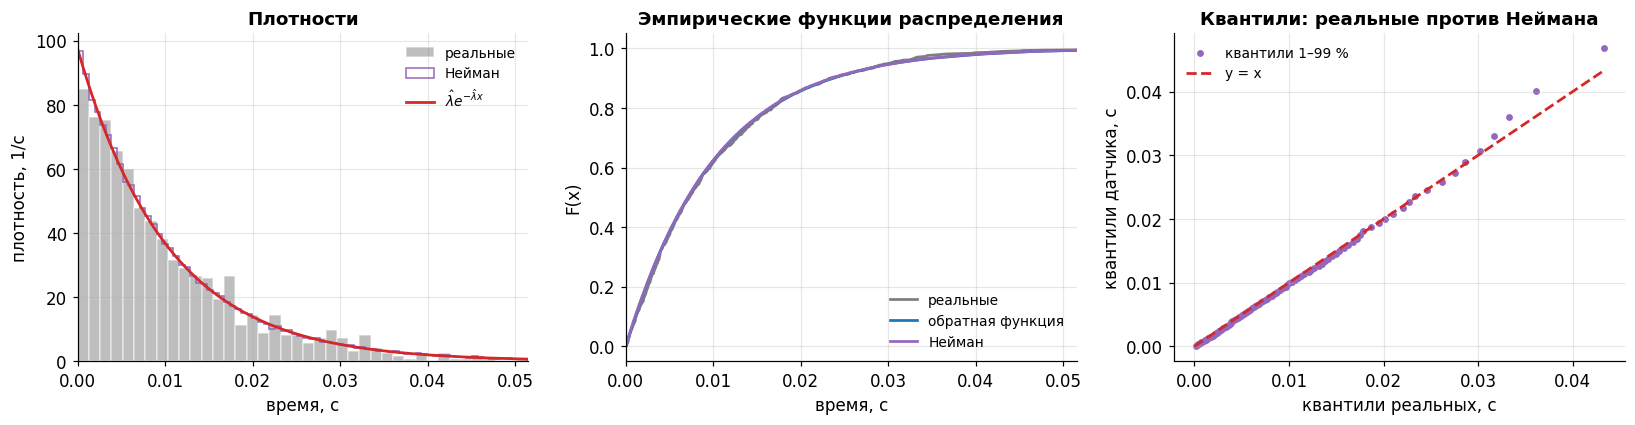

In [26]:
#@title Плотности, функции распределения и квантили: реальные данные и датчики
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
xx = np.linspace(0, np.quantile(real, .995), 400)
ax[0].hist(real, bins=40, range=(0, xx.max()), density=True, color=COLORS["real"], alpha=.5, edgecolor="white", label="реальные")
ax[0].hist(g_neu, bins=80, range=(0, xx.max()), density=True, histtype="step", lw=1.6, color=COLORS["gen"], label="Нейман")
ax[0].plot(xx, lam * np.exp(-lam * xx), color=COLORS["theory"], label=r"$\hat\lambda e^{-\hat\lambda x}$"); ax[0].set_xlim(0, xx.max())
decorate(ax[0], "Плотности", "время, с", "плотность, 1/с")
for g, col, lab in [(real, COLORS["real"], "реальные"), (g_inv, COLORS["open"], "обратная функция"), (g_neu, COLORS["gen"], "Нейман")]:
    s = np.sort(g); ax[1].plot(s, np.arange(1, len(s) + 1) / len(s), color=col, label=lab)
ax[1].set_xlim(0, xx.max()); decorate(ax[1], "Эмпирические функции распределения", "время, с", "F(x)")
q = np.linspace(.01, .99, 99)
ax[2].scatter(np.quantile(real, q), np.quantile(g_neu, q), s=12, color=COLORS["gen"], label="квантили 1–99 %")
mq = np.quantile(real, .99); ax[2].plot([0, mq], [0, mq], color=COLORS["theory"], ls="--", label="y = x")
decorate(ax[2], "Квантили: реальные против Неймана", "квантили реальных, с", "квантили датчика, с")
plt.tight_layout(); plt.show()

> ✏️ **Правка КТвД № 8.** У трёх графиков датчика не было подписей осей и единиц, цвета по умолчанию. Добавлены подписи, единицы, общие цвета. Подробно — [журнал правок](#s17).

<a id="s10-4" name="s10-4"></a>
### 10.4 Тесты

In [27]:
#@title Тест: MT19937 совпадает с эталоном
ref = MT19937(5489)
assert [ref.u32() for _ in range(3)] == [3499211612, 581869302, 3890346734]
print("MT19937 совпадает с эталоном")

MT19937 совпадает с эталоном


In [28]:
#@title Критерий КС против теории и против реальных данных, время работы
rows=[]
for name, g, t in [("Обратная функция", g_inv, t_inv), ("Нейман (без ln)", g_neu, t_neu)]:
    ks_th = stats.kstest(g, 'expon', args=(0, 1/lam))          # против теоретической Exp(λ̂)
    ks_re = stats.ks_2samp(g, real)                              # против реальных данных
    rows.append({"генератор": name, "КС против теории: D": ks_th.statistic, "p": ks_th.pvalue,
                 "КС против реальных: D": ks_re.statistic, "p (реальные)": ks_re.pvalue,
                 f"время на {N} чисел, с": round(t,3)})
display(pd.DataFrame(rows).round(4))

,генератор,КС против теории: D,p,КС против реальных: D,p (реальные),"время на 100000 чисел, с"
0,Обратная функция,0.0025,0.5505,0.0245,0.6083,0.988
1,Нейман (без ln),0.0028,0.4013,0.0252,0.5677,2.607


In [29]:
#@title Автотесты генератора
# автотесты генератора
def test_exp_generators():
    for gen_fn in (exp_inverse, exp_neumann):
        ps = [stats.kstest(gen_fn(MT19937(s), 2.0, 3000), 'expon', args=(0, .5)).pvalue for s in range(1, 41)]
        assert stats.kstest(ps, 'uniform').pvalue > 0.01, gen_fn.__name__   # p-значения ~ U(0,1) при верной H0
        x = gen_fn(MT19937(7), 2.0, 50_000)
        assert abs(x.mean() - .5) < 4*0.5/np.sqrt(50_000)                      # среднее в пределах 4σ
        assert x.min() >= 0
def test_reproducibility():
    assert np.allclose(exp_neumann(MT19937(1), 1, 10), exp_neumann(MT19937(1), 1, 10))

class CountingMT(MT19937):
    """MT19937 со счётчиком обращений к U(0,1) — для проверки стоимости датчиков."""
    calls = 0
    def random(self):
        self.calls += 1
        return super().random()

def test_uniform():
    r = MT19937(42); u = np.array([r.random() for _ in range(40_000)])
    assert 0 < u.min() and u.max() < 1                                         # строго (0, 1)
    assert stats.kstest(u, "uniform").pvalue > 0.001                            # равномерность
    assert abs(np.corrcoef(u[:-1], u[1:])[0, 1]) < 4 / np.sqrt(len(u))          # нет корреляции соседних

def test_neumann_cost():
    r = CountingMT(3); exp_neumann(r, 1.0, 20_000)
    assert abs(r.calls / 20_000 - math.e ** 2 / (math.e - 1)) < 0.1             # теория e²/(e−1) ≈ 4.30

tests = [test_exp_generators, test_reproducibility, test_uniform, test_neumann_cost]
for t in tests:
    t(); print(f"✓ {t.__name__}")
print(f"Все автотесты пройдены: {len(tests)} из {len(tests)}")

✓ test_exp_generators
✓ test_reproducibility
✓ test_uniform
✓ test_neumann_cost
Все автотесты пройдены: 4 из 4


> ✏️ **Правка КТвД № 9.** Добавлены 2 автотеста: равномерность и независимость $U$, стоимость датчика Неймана $e^2/(e-1)$. Подробно — [журнал правок](#s17).

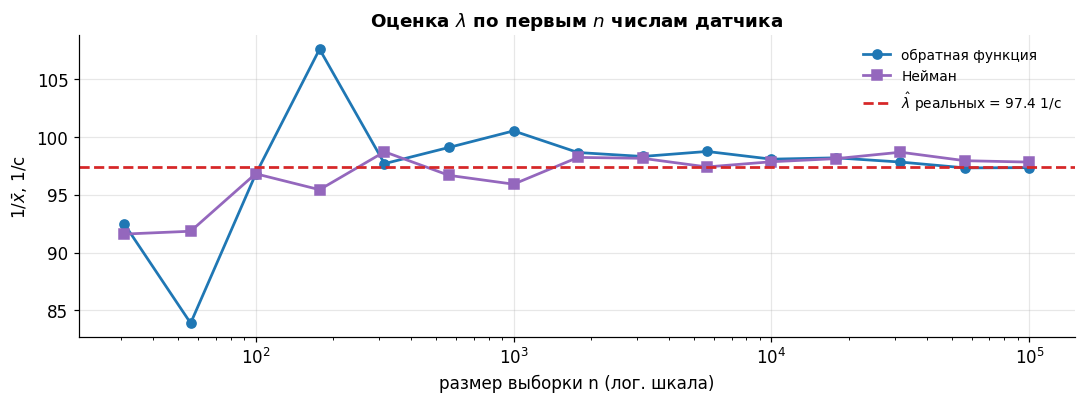

In [30]:
#@title Состоятельность оценки λ по выборке генератора
sizes = np.unique(np.logspace(1.5, 5, 15).astype(int))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(sizes, [1 / g_inv[:s].mean() for s in sizes], "o-", color=COLORS["open"], label="обратная функция")
ax.plot(sizes, [1 / g_neu[:s].mean() for s in sizes], "s-", color=COLORS["gen"], label="Нейман")
ax.axhline(lam, color=COLORS["theory"], ls="--", label=fr"$\hat\lambda$ реальных = {lam:.1f} 1/с")
ax.set_xscale("log")
decorate(ax, r"Оценка $\lambda$ по первым $n$ числам датчика", "размер выборки n (лог. шкала)", r"$1/\bar x$, 1/с")
plt.tight_layout(); plt.show()

<a id="s10-5" name="s10-5"></a>
### 10.5 Итоги

Оба генератора воспроизводят целевое Exp(λ̂), λ̂ = 97.41 с⁻¹ (n = 964 реальных значений).
Выборка из 100 000 чисел (из генератора) в сравнении с теорией и реальными данными:

| метрика | теория | реальные | обр. функция | Нейман |
|---------|--------|----------|--------------|--------|
| среднее, с | 0.01027 | 0.01027 | 0.01027 | 0.01022 |
| ст. отклонение, с | 0.01027 | 0.00973 | 0.01032 | 0.01023 |
| медиана | 0.00712 | 0.00728 | 0.00710 | 0.00709 |
| асимметрия | 2 | 1.68 | 2.03 | 2.01 |
| экс. эксцесс | 6 | 3.59 | 6.23 | 6.04 |
| q05 / q95 | 0.00053 / 0.03075 | 0.00056 / 0.03016 | 0.00054 / 0.03075 | 0.00052 / 0.03072 |

- КС против теоретической Exp(λ̂): D = 0.0025 (p = 0.55) у обратной функции, D = 0.0028 (p = 0.40) у Неймана, оба не отвергаются.
- КС против реальных данных: p = 0.61 и p = 0.57, выборки генераторов неотличимы от реальной.
- Автотесты (p-значение ~ U(0,1) по 40 зёрнам генератора, среднее в пределах 4σ, воспроизводимость) пройдены.
- Скорость на 100 000 чисел: 0.68 с (обратная функция) и 2.52 с (Нейман), то есть примерно в 3.7 раза медленнее — метод Неймана тратит ≈ 4.3 обращения к U на число против одного, зато не вызывает ln.
- У реальной выборки асимметрия и эксцесс ниже теоретических (1.68 и 3.59 против 2 и 6). Эти моменты высоких порядков при n = 964 оцениваются нестабильно (хвост даёт большой вклад), а КС расхождения не выявил, поэтому мы считаем это выборочной вариацией.
- Вывод: оба датчика корректны и применимы; обратная функция проще и быстрее, Нейман интересен как датчик без логарифмов.

[↑ к содержанию](#toc)

<a id="s10-6" name="s10-6"></a>
## 10.6 Датчик 2: нормальное распределение $\mathcal N(\mu, \sigma^2)$ для $I_{open}$

**Описание.** Второй датчик — для третьей СВ, тока в открытом состоянии: $I_{open} \sim \mathcal N(\hat\mu, \hat\sigma^2)$, $\hat\mu = \bar I$, $\hat\sigma = s$. Благодаря стандартизации из [5.2](#s5-2) достаточно генерировать $Z \sim \mathcal N(0,1)$ и возвращать $\hat\mu + \hat\sigma Z$. Реализованы два метода из таблицы задания поверх того же MT19937.

**Математическое обоснование.**

*Метод Бокса — Мюллера.* Для пары независимых $Z_1, Z_2 \sim \mathcal N(0,1)$ совместная плотность $\frac{1}{2\pi}e^{-(z_1^2+z_2^2)/2}$ зависит только от радиуса. В полярных координатах $R^2 = Z_1^2 + Z_2^2 \sim \chi^2(2) = \mathrm{Exp}(1/2)$, угол $\Theta \sim U(0, 2\pi)$, и они независимы. По методу обратной функции $R = \sqrt{-2\ln U_1}$, $\Theta = 2\pi U_2$:
$$Z_1 = \sqrt{-2\ln U_1}\cos 2\pi U_2, \qquad Z_2 = \sqrt{-2\ln U_1}\sin 2\pi U_2.$$

*Полярный метод Марсальи* (Кнут, т. 2, алг. 3.4.1-P) убирает $\sin$ и $\cos$. Берём $V_1, V_2 \sim U(-1, 1)$ и оставляем только точки внутри единичного круга: $S = V_1^2 + V_2^2 < 1$ (вероятность $\pi/4$). Тогда $S \sim U(0,1)$ и не зависит от направления $(V_1, V_2)/\sqrt S = (\cos\Theta, \sin\Theta)$. Подставляя $U_1 = S$:
$$Z_{1,2} = V_{1,2}\sqrt{\frac{-2\ln S}{S}}.$$
Стоимость: на пару чисел в среднем $2 \cdot \frac{4}{\pi}$ обращений к $U$, то есть $\frac{4}{\pi} \approx 1.27$ на одно число.

<sub>✏️ Раздел добавлен КТвД — см. [журнал правок](#s17), пункт А3.</sub>

,"теория N(μ̂, σ̂²)",реальные,Бокс — Мюллер,полярный Марсальи
"среднее, пА",17.5676,17.5676,17.5648,17.5711
"ст. отклонение, пА",1.7335,1.7335,1.7332,1.7360
"медиана, пА",17.5676,17.5673,17.5649,17.5767
асимметрия,0.0000,0.0019,0.0063,-0.0122
изб. эксцесс,0.0000,0.0007,0.0138,0.0170
"квантиль 5 %, пА",14.7161,14.7115,14.7192,14.7015
"квантиль 95 %, пА",20.4190,20.4181,20.4127,20.4228


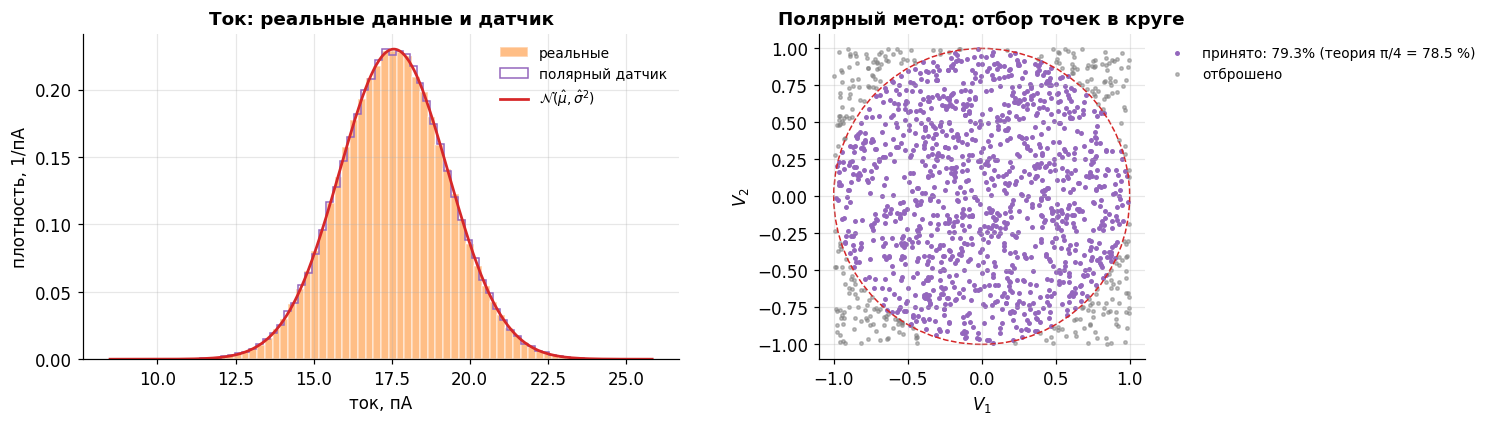

In [31]:
#@title Код: датчики Бокса — Мюллера и полярный
def normal_box_muller(rng, mu, sigma, n):
    out = np.empty(n)
    for i in range(0, n, 2):
        r = math.sqrt(-2 * math.log(rng.random())); t = 2 * math.pi * rng.random()
        out[i] = r * math.cos(t)
        if i + 1 < n: out[i + 1] = r * math.sin(t)
    return mu + sigma * out

def normal_polar(rng, mu, sigma, n):
    out = np.empty(n); i = 0
    while i < n:
        v1, v2 = 2 * rng.random() - 1, 2 * rng.random() - 1
        s = v1 * v1 + v2 * v2
        if s >= 1 or s == 0:
            continue                                   # точка вне круга — отбрасываем
        f = math.sqrt(-2 * math.log(s) / s)
        out[i] = v1 * f; i += 1
        if i < n: out[i] = v2 * f; i += 1
    return mu + sigma * out

mu_I, sd_I = current_open.mean(), current_open.std(ddof=1)
N_I = 100_000
gens_I = {}
for name, fn in [("Бокс — Мюллер", normal_box_muller), ("полярный Марсальи", normal_polar)]:
    r = CountingMT(2026); t0 = time.perf_counter(); g = fn(r, mu_I, sd_I, N_I)
    gens_I[name] = dict(x=g, t=time.perf_counter() - t0, calls=r.calls / N_I)

def metrics_I(x):
    return {"среднее, пА": x.mean(), "ст. отклонение, пА": x.std(ddof=1), "медиана, пА": np.median(x), "асимметрия": stats.skew(x),
            "изб. эксцесс": stats.kurtosis(x), "квантиль 5 %, пА": np.quantile(x, .05), "квантиль 95 %, пА": np.quantile(x, .95)}
th_I = {"среднее, пА": mu_I, "ст. отклонение, пА": sd_I, "медиана, пА": mu_I, "асимметрия": 0.0, "изб. эксцесс": 0.0,
        "квантиль 5 %, пА": mu_I + sd_I * stats.norm.ppf(.05), "квантиль 95 %, пА": mu_I + sd_I * stats.norm.ppf(.95)}
display(pd.DataFrame({"теория N(μ̂, σ̂²)": th_I, "реальные": metrics_I(current_open),
                      **{k: metrics_I(v["x"]) for k, v in gens_I.items()}}).round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
xx = np.linspace(current_open.min(), current_open.max(), 400)
ax[0].hist(current_open, bins=70, density=True, color=COLORS["current"], alpha=.5, edgecolor="white", label="реальные")
ax[0].hist(gens_I["полярный Марсальи"]["x"], bins=70, density=True, histtype="step", lw=1.6, color=COLORS["gen"], label="полярный датчик")
ax[0].plot(xx, stats.norm.pdf(xx, mu_I, sd_I), color=COLORS["theory"], label=r"$\mathcal{N}(\hat\mu, \hat\sigma^2)$")
decorate(ax[0], "Ток: реальные данные и датчик", "ток, пА", "плотность, 1/пА")
r = MT19937(11); pts = np.array([[2 * r.random() - 1, 2 * r.random() - 1] for _ in range(1500)]); inside = (pts ** 2).sum(1) < 1
ax[1].scatter(*pts[inside].T, s=5, color=COLORS["gen"], label=f"принято: {inside.mean():.1%} (теория π/4 = 78.5 %)")
ax[1].scatter(*pts[~inside].T, s=5, color=COLORS["real"], alpha=.5, label="отброшено")
ax[1].add_patch(plt.Circle((0, 0), 1, fill=False, color=COLORS["theory"], ls="--")); ax[1].set_aspect("equal")
decorate(ax[1], "Полярный метод: отбор точек в круге", "$V_1$", "$V_2$")
ax[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9)
plt.tight_layout(); plt.show()

In [32]:
#@title Тесты: согласие, стоимость, автотесты нормального датчика
sub_I = np.random.default_rng(0).choice(current_open, 20_000, replace=False)
rows = []
for name, v in gens_I.items():
    rows.append({"датчик": name,
                 "КС против N(μ̂, σ̂²): p": stats.kstest(v["x"], stats.norm(mu_I, sd_I).cdf).pvalue,
                 "КС против реальных: p": stats.ks_2samp(v["x"], sub_I).pvalue,
                 "обращений к U на число": v["calls"],
                 "теория": 1.0 if "Бокс" in name else 4 / math.pi,
                 "время на 100 000, с": v["t"]})
tab_I = pd.DataFrame(rows).set_index("датчик"); display(tab_I.round(4))

def test_normal_generators():
    for fn in (normal_box_muller, normal_polar):
        ps = [stats.kstest(fn(MT19937(s), 0, 1, 2000), "norm").pvalue for s in range(1, 31)]
        assert stats.kstest(ps, "uniform").pvalue > 0.01, fn.__name__           # p-значения ~ U(0,1) при верной H0
        x = fn(MT19937(5), 3.0, 2.0, 40_000)
        assert abs(x.mean() - 3) < 4 * 2 / np.sqrt(len(x)) and abs(x.std(ddof=1) / 2 - 1) < 0.03

def test_polar_cost():
    r = CountingMT(9); normal_polar(r, 0, 1, 20_000)
    assert abs(r.calls / 20_000 - 4 / math.pi) < 0.03                            # доля принятия π/4

for t in (test_normal_generators, test_polar_cost):
    t(); print(f"✓ {t.__name__}")

,"КС против N(μ̂, σ̂²): p",КС против реальных: p,обращений к U на число,теория,"время на 100 000, с"
датчик,,,,,
Бокс — Мюллер,0.6550,0.5041,1.0000,1.0000,0.2470
полярный Марсальи,0.4735,0.3056,1.2707,1.2732,0.3134


✓ test_normal_generators
✓ test_polar_cost


**Итоги.** Оба нормальных датчика работают: среднее, разброс и квантили совпадают с теорией, а критерий КС не может отличить их выборки ни от нормального закона, ни от реального тока. Разница между ними только в «цене». Полярному методу не нужны синус и косинус, но примерно каждую пятую пару точек он выбрасывает, поэтому тратит около $4/\pi \approx 1.27$ равномерных числа на одно значение. Это число мы получили и счётчиком, и в автотесте.


[↑ к содержанию](#toc)

<a id="s10-7" name="s10-7"></a>
## 10.7 Исследование алгоритмов датчиков

| # | алгоритм | распределения | где используется | сильные стороны | слабые стороны | источник |
|---|---|---|---|---|---|---|
| 1 | **Вихрь Мерсенна MT19937** | $U(0,1)$ — база для всех датчиков | Python `random`, NumPy `RandomState`, R, MATLAB | период $2^{19937}-1$, 623-мерная равномерность, быстрый | 2.5 КБ состояния; не криптостойкий; проваливает тесты линейной сложности из набора TestU01 | [2] |
| 2 | **Метод обратной функции** | любые с явной $F^{-1}$: экспонента, Вейбулл, Коши, Парето | универсальный метод, квази-Монте-Карло, копулы | точный, монотонный (сохраняет порядок $U$), одно $U$ на число | нужна явная $F^{-1}$, иначе численное обращение | [4], гл. 2 |
| 3 | **Нейман — Форсайт, «чёт-нечет»** | экспонента; обобщение — плотности вида $e^{-G(x)}$ | устройства без аппаратной поддержки дробных чисел, точная арифметика | без логарифмов, только сравнения | ≈ 4.3 $U$ на число | [1], [3] |
| 4 | **Бокс — Мюллер** | нормальное | учебные и простые реализации | точный, два числа за раз | $\ln$, $\sqrt{}$, $\sin$, $\cos$ на каждую пару | [10] |
| 5 | **Полярный метод Марсальи** | нормальное | GNU libstdc++ `normal_distribution`, Java `nextGaussian` | без тригонометрии | отбор: 21.5 % пар впустую | [1], [11] |
| 6 | **Метод Неймана (метод отбора)** | любые с ограниченной плотностью под мажорантой $c\,g(x)$ | гамма, бета, усечённые распределения | универсальный и точный | эффективность $1/c$: плохая мажоранта — много отказов | [4], гл. 2 |
| 7 | **Зиккурат / прямоугольник-клин-хвост** | нормальное, экспонента (монотонные и симметричные плотности) | NumPy `Generator.normal` / `exponential`, Julia, MATLAB `randn` | ≈ 99 % случаев — одно сравнение и умножение | таблицы, сложный хвост | [1], [12] |
| 8 | **Метод отношений равномерных величин** | нормальное, гамма, Стьюдент | гамма-датчики, $t$-распределение | простой отбор в области на плоскости | отбор и ветвления | [1], [13] |
| 9 | **Метод псевдонимов** | дискретные с конечным носителем | выбор категории по весам: обработка текстов, графы, игры | $O(1)$ на число после $O(n)$ подготовки | только дискретные, нужна таблица | [14] |
| 10 | **Метод суперпозиции (смеси)** | смеси: гипер-экспонента, смеси нормальных | многосостоянийные каналы, смесь сортов вин ([12](#s12)) | сводит сложное к простому | нужно разложение на компоненты | [4], [15] |

**Пример использования в нашей теме.** Реальный ChR2 имеет несколько открытых состояний, и время открытия — смесь экспонент $f(t) = \sum_j p_j \lambda_j e^{-\lambda_j t}$. Датчик для неё: **метод псевдонимов** выбирает состояние $j$ с вероятностью $p_j$, затем **метод обратной функции** генерирует $\mathrm{Exp}(\lambda_j)$ — это и есть метод суперпозиции. Ниже — проверка на смеси двух экспонент.

<sub>✏️ Раздел добавлен КТвД — см. [журнал правок](#s17), пункт А3.</sub>

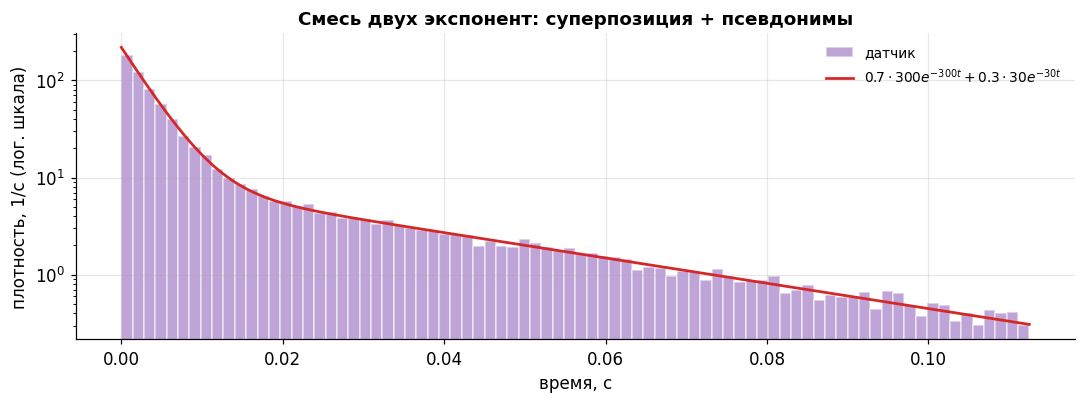

Критерий КС против теоретической смеси: p = 0.811


In [33]:
#@title Пример: суперпозиция + псевдонимы для смеси экспонент
def alias_table(p):
    """Метод псевдонимов (Walker, Vose): O(n) подготовка, O(1) выбор."""
    n = len(p); q = np.array(p, float) * n; alias = np.zeros(n, int)
    small = [i for i in range(n) if q[i] < 1]; large = [i for i in range(n) if q[i] >= 1]
    while small and large:
        s, l = small.pop(), large.pop(); alias[s] = l; q[l] -= 1 - q[s]
        (small if q[l] < 1 else large).append(l)
    for i in small + large: q[i] = 1.0
    return q, alias

def hyperexp(rng, p, lams, n):
    q, alias = alias_table(p); k = len(p); out = np.empty(n)
    for i in range(n):
        j = int(rng.random() * k); j = j if rng.random() < q[j] else alias[j]
        out[i] = -math.log(rng.random()) / lams[j]
    return out

p_mix, lam_mix = [0.7, 0.3], [300.0, 30.0]          # «быстрое» и «медленное» открытое состояние, 1/с
xh = hyperexp(MT19937(1), p_mix, lam_mix, 50_000)
f_mix = lambda t: sum(p * l * np.exp(-l * t) for p, l in zip(p_mix, lam_mix))
F_mix = lambda t: 1 - sum(p * np.exp(-l * t) for p, l in zip(p_mix, lam_mix))
fig, ax = plt.subplots(figsize=(10, 3.8))
tt = np.linspace(0, np.quantile(xh, .99), 400)
ax.hist(xh, bins=80, range=(0, tt.max()), density=True, color=COLORS["gen"], alpha=.6, edgecolor="white", label="датчик")
ax.plot(tt, f_mix(tt), color=COLORS["theory"], label=r"$0.7\cdot300e^{-300t} + 0.3\cdot30e^{-30t}$")
ax.set_yscale("log")
decorate(ax, "Смесь двух экспонент: суперпозиция + псевдонимы", "время, с", "плотность, 1/с (лог. шкала)")
plt.tight_layout(); plt.show()
print(f"Критерий КС против теоретической смеси: p = {stats.kstest(xh, F_mix).pvalue:.3f}")

[↑ к содержанию](#toc)

<a id="s11" name="s11"></a>
## 11. Итоги спринта 2 и таблица оценок

В итоге у нас **четыре датчика**, и все работают на нашем собственном вихре Мерсенна. Два из них дают показательное распределение для $T_{open}$ (обратная функция и метод Неймана — Форсайта), ещё два — нормальное для $I_{open}$ (Бокс — Мюллер и полярный метод). Отдельно мы попробовали метод суперпозиции вместе с методом псевдонимов на смеси экспонент ([10.7](#s10-7)).

Критерий КС не отличает выборки ни одного датчика ни от теоретического закона, ни от реальных данных. Самый простой и быстрый — метод обратной функции. Метод Неймана и полярный метод обходятся без логарифма и тригонометрии, но за это тратят больше равномерных чисел. Сколько именно, мы посчитали заранее ($e^2/(e-1)$ и $4/\pi$), а потом проверили счётчиком — совпало. Все автотесты пройдены.

**Версионирование генератора** (логика итераций):

| версия | изменение | причина |
|--------|-----------|---------|
| v0.1 | $-\ln U/\lambda$ на стандартном генераторе NumPy | базовая проверка идеи |
| v0.2 | собственный MT19937 + сверка с эталоном | генератор должен быть свой и воспроизводимый |
| v0.3 | $U \in (0,1)$ строго (сдвиг на половину младшего разряда) | исключить $\ln 0$ |
| v0.4 | датчик Неймана без логарифмов | второй метод из таблицы, сравнение скорости |
| v0.5 | автотесты (равномерность p-значений, правило 4σ, повторяемость по зерну) | регрессионная проверка при правках |
| v0.6 | счётчик обращений к $U$, тесты стоимости и равномерности $U$ | проверить теоретическую стоимость $e^2/(e-1)$ |
| v0.7 | нормальные датчики (Бокс — Мюллер, полярный) для $I_{open}$ | третья СВ нормальна — нужен свой датчик |
| v0.8 | суперпозиция + метод псевдонимов | реальный ChR2 даёт смесь экспонент |

**Итоговая таблица метрик**

In [34]:
#@title Итоговая таблица метрик всех датчиков
ks_rows = []
for name, g in [("обратная функция", g_inv), ("Нейман (без ln)", g_neu)]:
    ks_rows.append({"датчик": name, "цель": "Exp(λ̂) · T_open",
                    "p: КС против теории": stats.kstest(g, "expon", args=(0, 1 / lam)).pvalue,
                    "p: КС против реальных": stats.ks_2samp(g, real).pvalue,
                    "U на число": 1.0 if name.startswith("обр") else math.e ** 2 / (math.e - 1),
                    "время на 100 000, с": t_inv if name.startswith("обр") else t_neu})
for name, row in tab_I.iterrows():
    ks_rows.append({"датчик": name, "цель": "N(μ̂, σ̂²) · I_open",
                    "p: КС против теории": row["КС против N(μ̂, σ̂²): p"], "p: КС против реальных": row["КС против реальных: p"],
                    "U на число": row["обращений к U на число"], "время на 100 000, с": row["время на 100 000, с"]})
final = pd.DataFrame(ks_rows).set_index("датчик")
final["вердикт"] = np.where((final["p: КС против теории"] > .05) & (final["p: КС против реальных"] > .05), "✓ согласуется", "✗")
display(final.round(4))

,цель,p: КС против теории,p: КС против реальных,U на число,"время на 100 000, с",вердикт
датчик,,,,,,
обратная функция,Exp(λ̂) · T_open,0.5505,0.6083,1.0000,0.9879,✓ согласуется
Нейман (без ln),Exp(λ̂) · T_open,0.4013,0.5677,4.3003,2.6069,✓ согласуется
Бокс — Мюллер,"N(μ̂, σ̂²) · I_open",0.6550,0.5041,1.0000,0.2470,✓ согласуется
полярный Марсальи,"N(μ̂, σ̂²) · I_open",0.4735,0.3056,1.2707,0.3134,✓ согласуется


**Таблица оценок** (cat_mark_table, формат по шаблону ТЗ)

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| 3.1 | https://github.com/pinturia-star/lab01-stochastics | 1.0 | метрики датчиков и реальных данных совпадают ([10.3](#s10-3), итоговая таблица) |
| 3.2 | [#s10](#s10) | 1.0 | методы из таблицы: обратная функция, «чёт-нечет», Бокс — Мюллер, полярный, суперпозиция, псевдонимы |
| 3.3 | [#s10-2](#s10-2) | 1.0 | мат. обоснование всех методов и их стоимости |
| 3.4 | [#s15](#s15) | 1.0 | литература: книги и статьи из журналов ACM, AMS, SIAM, JASA |
| доп | [#s10-6](#s10-6) | + | другой алгоритм датчика, второе распределение |
| доп | [#s10-4](#s10-4) | + | автотесты генератора (6 тестов) |
| доп | [#s11](#s11) | + | версионирование, итоговая таблица метрик |
| доп | [#s10-7](#s10-7) | + | исследование 10 алгоритмов датчиков |
| доп | [#s12](#s12) | + | доп. датасет КТвД: условная независимость при общем факторе |

[↑ к содержанию](#toc)

# Часть КТвД

<a id="s12" name="s12"></a>
## 12. Доп. датасет: химический состав вин (UCI Wine)

<a id="s12-1" name="s12-1"></a>
### 12.1 Описание

Датасет UCI Wine (178 образцов, 3 сорта винограда из одного региона Италии). Берём две величины одной природы, концентрации веществ в образце:
- $X_1$ — содержание спирта, % об. (`alcohol`);
- $X_2$ — содержание яблочной кислоты, г/л (`malic_acid`).

Обе зависят от погоды, почвы, зрелости ягод и технологии брожения. Сорт задаёт лишь средний уровень, а значение конкретного образца по формуле не вычисляется.

In [35]:
#@title Загрузка датасета и описательные статистики
from sklearn.datasets import load_wine
w = load_wine(as_frame=True)
wine = w.frame.rename(columns={"target": "cultivar"})
X1, X2 = wine["alcohol"].to_numpy(), wine["malic_acid"].to_numpy()
RU = {"alcohol": "спирт, % об.", "malic_acid": "яблочная кислота, г/л"}
display(wine[["alcohol", "malic_acid"]].describe().T.round(3)
        .rename(index=RU, columns={"count": "объём", "mean": "среднее", "std": "ст. откл.", "min": "минимум",
                                   "25%": "25 %", "50%": "медиана", "75%": "75 %", "max": "максимум"}))

,объём,среднее,ст. откл.,минимум,25 %,медиана,75 %,максимум
"спирт, % об.",178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
"яблочная кислота, г/л",178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80


<a id="s12-2" name="s12-2"></a>
### 12.2 Разведочный анализ

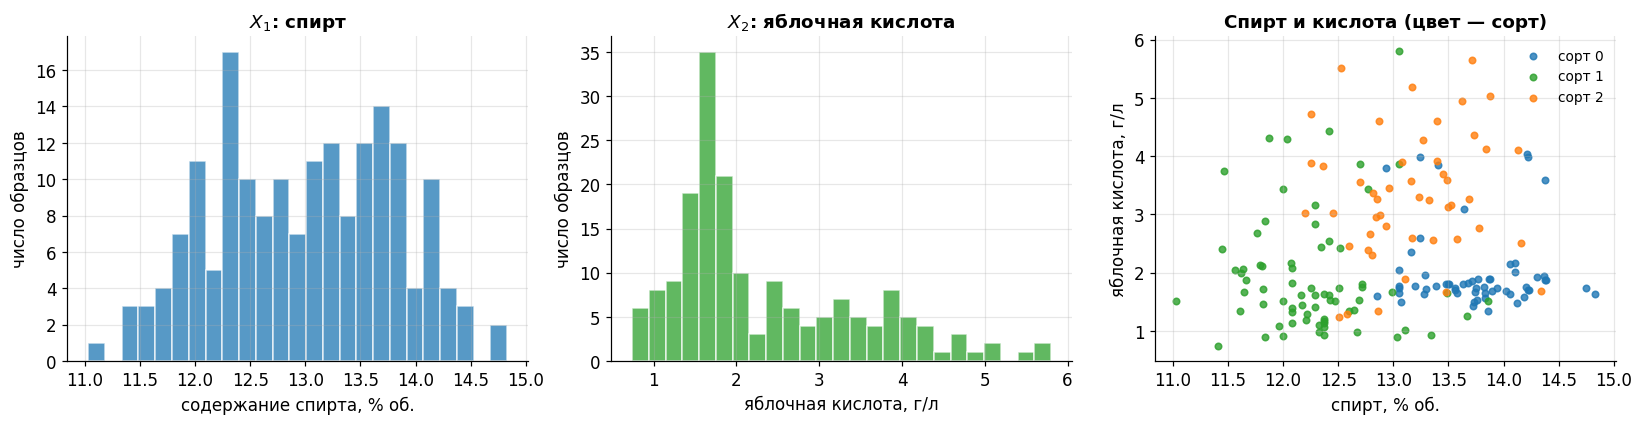

спирт: асимметрия = -0.05, эксцесс = -0.86, Шапиро p = 0.02
яблочная кислота: асимметрия = 1.03, эксцесс = 0.26, Шапиро p = 2.95e-10


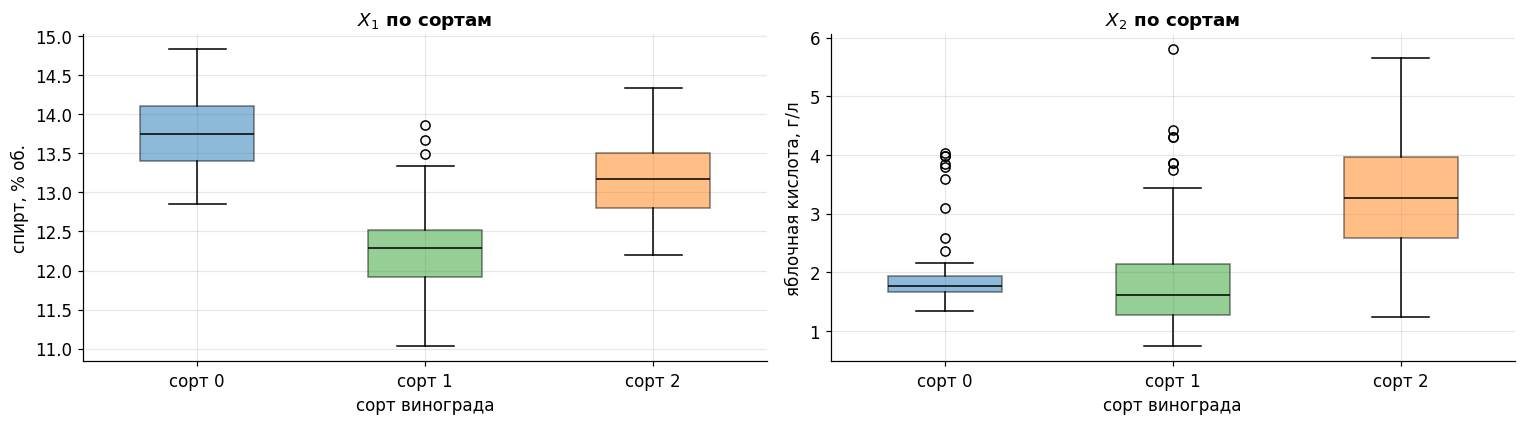

Шапиро после стандартизации внутри сорта: спирт p = 0.258, кислота p = 3.29e-11


In [36]:
#@title Гистограммы, диаграмма рассеяния, ящики по сортам
CULT = {0: COLORS["open"], 1: COLORS["closed"], 2: COLORS["current"]}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(X1, bins=25, color=COLORS["open"], alpha=.75, edgecolor="white")
decorate(ax[0], "$X_1$: спирт", "содержание спирта, % об.", "число образцов", legend=False)
ax[1].hist(X2, bins=25, color=COLORS["closed"], alpha=.75, edgecolor="white")
decorate(ax[1], "$X_2$: яблочная кислота", "яблочная кислота, г/л", "число образцов", legend=False)
for c, col in CULT.items():
    s = wine[wine.cultivar == c]; ax[2].scatter(s.alcohol, s.malic_acid, s=18, color=col, alpha=.8, label=f"сорт {c}")
decorate(ax[2], "Спирт и кислота (цвет — сорт)", "спирт, % об.", "яблочная кислота, г/л")
plt.tight_layout(); plt.show()
for name, x in [("спирт", X1), ("яблочная кислота", X2)]:
    print(f"{name}: асимметрия = {stats.skew(x):.2f}, эксцесс = {stats.kurtosis(x):.2f}, Шапиро p = {stats.shapiro(x).pvalue:.3g}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, col, unit, ttl in [(ax[0], "alcohol", "спирт, % об.", "$X_1$ по сортам"), (ax[1], "malic_acid", "яблочная кислота, г/л", "$X_2$ по сортам")]:
    data = [wine[wine.cultivar == c][col] for c in CULT]
    bp = a.boxplot(data, patch_artist=True, widths=.5)
    for patch, c in zip(bp["boxes"], CULT.values()): patch.set_facecolor(c); patch.set_alpha(.5)
    for m in bp["medians"]: m.set_color("k")
    a.set_xticks([1, 2, 3], [f"сорт {c}" for c in CULT])
    decorate(a, ttl, "сорт винограда", unit, legend=False)
plt.tight_layout(); plt.show()

# Z-нормализация внутри сорта: убираем «смешение сортов»
z_in = wine.groupby("cultivar")[["alcohol", "malic_acid"]].transform(lambda v: (v - v.mean()) / v.std(ddof=1))
print("Шапиро после стандартизации внутри сорта: "
      f"спирт p = {stats.shapiro(z_in.alcohol).pvalue:.3g}, кислота p = {stats.shapiro(z_in.malic_acid).pvalue:.3g}")

Спирт распределён почти симметрично, но вершина у него «плоская» (эксцесс отрицательный), и нормальность отвергается ($p \approx 0.02$). Причина видна на ящиках: в данных смешаны три сорта со средними 12.3, 13.2 и 13.7 % об. У яблочной кислоты длинный правый хвост (асимметрия больше 1), так что о нормальности и говорить нечего. Если вычесть из каждого образца среднее его сорта и поделить на разброс внутри сорта, спирт становится нормальным, а кислота так и остаётся скошенной.


<a id="s12-3" name="s12-3"></a>
### 12.3 Доказательство случайности

Если бы величина вычислялась детерминированно, её значение однозначно определялось бы известными факторами. Проверим это двумя способами:
1. Разброс внутри одного сорта: если $X$ — функция сорта, внутригрупповая дисперсия равна нулю.
2. Регрессия на все остальные 12 признаков: при детерминированной зависимости $R^2 = 1$ на отложенной выборке.

In [37]:
#@title Внутригрупповой разброс и R² по остальным признакам
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold
for name in ["alcohol", "malic_acid"]:
    g = wine.groupby("cultivar")[name]
    print(f"{RU[name]}: доля внутригрупповой дисперсии = {(g.var(ddof=1)*(g.count()-1)).sum()/((len(wine)-1)*wine[name].var(ddof=1)):.2f}")
    Xo = wine.drop(columns=[name, "cultivar"])
    # данные упорядочены по сортам, поэтому фолды обязательно перемешиваем
    r2 = cross_val_score(LinearRegression(), Xo, wine[name], cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
    print(f"   R² на кросс-валидации по остальным признакам = {r2.mean():.2f} ± {r2.std():.2f}")

спирт, % об.: доля внутригрупповой дисперсии = 0.39
   R² на кросс-валидации по остальным признакам = 0.49 ± 0.14
яблочная кислота, г/л: доля внутригрупповой дисперсии = 0.70
   R² на кросс-валидации по остальным признакам = 0.28 ± 0.13


Внутри одного сорта разброс никуда не девается: для спирта это 39 % всей дисперсии, для кислоты — 70 %. Регрессия по всем остальным 12 признакам тоже не спасает: на отложенных данных $R^2$ около 0.5 для спирта и 0.3 для кислоты, до единицы далеко. Значит, даже зная сорт и весь остальной химический состав, точное значение мы не получим — обе величины случайные.

*Почему фолды перемешаны.* Строки датасета идут по сортам подряд. Без перемешивания модель учится на одних сортах, а проверяется на другом, и $R^2$ выходит отрицательным. Это ошибка разбиения, а не свойство данных.


<a id="s12-4" name="s12-4"></a>
### 12.4 Независимость $X_1$ и $X_2$

$H_0$: $X_1$ и $X_2$ независимы, $\alpha = 0.05$. Критерии:
- Пирсон — линейная связь; Спирмен — монотонная;
- $\chi^2$ по таблице $2\times2$ «выше/ниже медианы» и по таблице $3\times3$ по терцилям — вторая замечает и **немонотонную** связь (например, «средний спирт ↔ высокая кислота»);
- взаимная информация $I(X_1; X_2) = \sum p(x_1,x_2)\log_2\frac{p(x_1,x_2)}{p(x_1)p(x_2)}$ с перестановочным тестом (перемешиваем $X_2$ 2000 раз).

Те же критерии повторяем внутри каждого сорта — это проверка **условной** независимости при фиксированном сорте.

In [38]:
#@title Корреляции и χ² для пары спирт–кислота
r_p = stats.pearsonr(X1, X2); r_s = stats.spearmanr(X1, X2)
tab = pd.crosstab(X1 > np.median(X1), X2 > np.median(X2)); chi = stats.chi2_contingency(tab)
print(f"Пирсон r = {r_p.statistic:.3f}, p = {r_p.pvalue:.3g}")
print(f"Спирмен r = {r_s.statistic:.3f}, p = {r_s.pvalue:.3g}")
print(f"χ² = {chi.statistic:.2f}, p = {chi.pvalue:.3g}")
for c in sorted(wine.cultivar.unique()):
    s = wine[wine.cultivar == c]; r = stats.spearmanr(s.alcohol, s.malic_acid)
    print(f"  сорт {c}: Спирмен r = {r.statistic:.2f}, p = {r.pvalue:.2g}")

# χ² по таблице 3×3 (терцили): ловит немонотонную связь, которую 2×2 по медианам пропускает
def chi2_terciles(x, y):
    t1 = np.digitize(x, np.quantile(x, [1/3, 2/3])); t2 = np.digitize(y, np.quantile(y, [1/3, 2/3]))
    ct = pd.crosstab(t1, t2); r = stats.chi2_contingency(ct)
    return ct, r.statistic, r.pvalue
ct33, chi33, p33 = chi2_terciles(X1, X2)
ct33.index = ["спирт: низкий", "средний", "высокий"]; ct33.columns = ["кислота: низкая", "средняя", "высокая"]
display(ct33)
print(f"χ² (3×3, терцили) = {chi33:.2f}, p = {p33:.2g}")
for c in sorted(wine.cultivar.unique()):
    s = wine[wine.cultivar == c]; _, ch, pc = chi2_terciles(s.alcohol.to_numpy(), s.malic_acid.to_numpy())
    print(f"  сорт {c}: χ² (3×3) = {ch:.2f}, p = {pc:.2g}")

# взаимная информация с перестановочным тестом
def mutual_info(x, y, bins=8):
    h, _, _ = np.histogram2d(x, y, bins); p = h / h.sum()
    px, py = p.sum(1, keepdims=True), p.sum(0, keepdims=True); nz = p > 0
    return float(np.sum(p[nz] * np.log2(p[nz] / (px @ py)[nz])))
rng_mi = np.random.default_rng(0)
mi = mutual_info(X1, X2); mi_null = np.array([mutual_info(X1, rng_mi.permutation(X2)) for _ in range(2000)])
print(f"Взаимная информация = {mi:.3f} бит, перестановочный p = {(np.sum(mi_null >= mi) + 1) / 2001:.3g}")

Пирсон r = 0.094, p = 0.21
Спирмен r = 0.140, p = 0.0615
χ² = 0.09, p = 0.764
  сорт 0: Спирмен r = -0.00, p = 0.99
  сорт 1: Спирмен r = -0.12, p = 0.34
  сорт 2: Спирмен r = 0.16, p = 0.26


,кислота: низкая,средняя,высокая
спирт: низкий,29,15,15
средний,13,16,29
высокий,14,31,16


χ² (3×3, терцили) = 22.41, p = 0.00017
  сорт 0: χ² (3×3) = 5.87, p = 0.21
  сорт 1: χ² (3×3) = 9.64, p = 0.047
  сорт 2: χ² (3×3) = 0.75, p = 0.95
Взаимная информация = 0.289 бит, перестановочный p = 0.024


**Вывод.** Обычные проверки связи не нашли: Пирсон ($r = 0.094$, $p = 0.21$), Спирмен ($r = 0.14$, $p = 0.06$) и таблица $2\times2$ по медианам ($p = 0.76$). Если бы мы на этом остановились, то написали бы «величины независимы» — и ошиблись бы.

Таблица $3\times3$ по терцилям показывает другое: $\chi^2 = 22.4$, $p \approx 0.0002$, и взаимная информация тоже значима. Связь есть, просто она не монотонная, поэтому корреляции её не видят. В таблице видно, откуда она берётся: низкий спирт идёт с низкой кислотой (это сорт 1), средний спирт — с высокой кислотой (сорт 2), высокий спирт — со средней кислотой (сорт 0).

Внутри каждого сорта связь пропадает: ни $\chi^2$, ни Спирмен ничего не находят (у сорта 1 $p = 0.047$, но при трёх проверках с поправкой Бонферрони порог $0.05/3 \approx 0.017$, так что и это незначимо). Получается, что спирт и кислота связаны не напрямую, а через общий фактор — сорт винограда.


<a id="s12-5" name="s12-5"></a>
### 12.5 Вывод по доп. датасету

Обе концентрации — случайные величины: даже внутри одного сорта они сильно разбросаны и плохо предсказываются по остальному составу. Спирт выглядит симметричным, но это смесь трёх сортов; внутри сорта он нормальный. Яблочная кислота скошена вправо.

Самое интересное — связь между ними. В целом по датасету спирт и кислота зависимы, но хитро, не по принципу «больше одного — больше другого». А внутри каждого сорта они независимы. Вывод для нас: если данные собраны из нескольких групп, одних корреляций мало, нужно проверять и немонотонную связь. В этом вина отличаются от $T_{open}$ и $T_{closed}$: там величины независимы без всяких условий.


[↑ к содержанию](#toc)

<a id="s13" name="s13"></a>
## 13. Интерактивный генератор

Переключателями выбирается распределение ($\mathrm{Exp}$ для $T_{open}$ или $\mathcal N$ для $I_{open}$) и метод, ползунками — $\lambda$, объём выборки и зерно генератора. График сравнивает выборку датчика с теоретической плотностью и выводит результат критерия КС. Для запуска нужны ячейки разделов [10.3](#s10-3) и [10.6](#s10-6). Та же демонстрация в виде отдельного приложения на **marimo** лежит в файле `lab01_generator_marimo.py` (запуск: `marimo run lab01_generator_marimo.py`).


In [39]:
#@title Интерактивный датчик
try:
    import ipywidgets as W
    def demo(распределение="Exp(λ) · T_open", метод="обратная функция", lam_=97.4, n=5000, seed=2026):
        r = CountingMT(int(seed))
        if распределение.startswith("Exp"):
            f = exp_inverse if метод == "обратная функция" else exp_neumann
            x = f(r, lam_, n); t = np.linspace(0, np.quantile(x, .995), 300)
            pdf, cdf, unit = lam_ * np.exp(-lam_ * t), (lambda v: 1 - np.exp(-lam_ * v)), "с"
        else:
            f = normal_box_muller if метод == "обратная функция" else normal_polar
            x = f(r, mu_I, sd_I, n); t = np.linspace(x.min(), x.max(), 300)
            pdf, cdf, unit = stats.norm.pdf(t, mu_I, sd_I), stats.norm(mu_I, sd_I).cdf, "пА"
        ks = stats.kstest(x, cdf)
        fig, ax = plt.subplots(figsize=(10, 3.8))
        ax.hist(x, bins=60, range=(t.min(), t.max()), density=True, color=COLORS["gen"], alpha=.6, edgecolor="white", label="датчик")
        ax.plot(t, pdf, color=COLORS["theory"], label="теория")
        decorate(ax, f"{распределение}: среднее = {x.mean():.4g} {unit}, КС: p = {ks.pvalue:.3f}, U на число = {r.calls / n:.2f}",
                 f"значение, {unit}", f"плотность, 1/{unit}")
        plt.tight_layout(); plt.show()
    W.interact(demo,
               распределение=W.ToggleButtons(options=["Exp(λ) · T_open", "N(μ̂, σ̂²) · I_open"]),
               метод=W.ToggleButtons(options=["обратная функция", "без ln / полярный"],
                                     tooltips=["Exp: −ln U/λ; N: Бокс — Мюллер", "Exp: Нейман; N: полярный Марсальи"]),
               lam_=W.FloatSlider(value=97.4, min=10, max=300, step=0.1, description="λ, 1/с"),
               n=W.IntSlider(value=5000, min=200, max=30000, step=200, description="n"),
               seed=W.IntText(value=2026, description="зерно"))
except ImportError:
    print("Не установлена библиотека виджетов. Установите её командой: pip install ipywidgets")

interactive(children=(ToggleButtons(description='распределение', options=('Exp(λ) · T_open', 'N(μ̂, σ̂²) · I_o…

[↑ к содержанию](#toc)

<a id="s14" name="s14"></a>
## 14. Критерии оценивания

**Основные требования**

| требование ТЗ | где выполнено |
|---|---|
| датасет по направлению, 3 случайные величины | [1](#s1), [2](#s2), [3](#s3), [5](#s5) |
| 2.1 доказательство случайности | [2.3](#s2-3), [3.3](#s3-3), [5.1](#s5-1) |
| 2.2 независимость величин одной природы | [4](#s4) |
| 2.3 состоятельность оценок (эмпирически) | [2.4](#s2-4), [3.4](#s3-4), [5.3](#s5-3), [10.4](#s10-4) |
| 2.4 разведочный анализ, нормализация | [2.2](#s2-2), [3.2](#s3-2), [5.2](#s5-2) |
| 2.5 выборка с возвращением и без | [6](#s6) |
| 2.6 математическая база распределения | [7](#s7) |
| 2.7 проверка гипотезы | [8](#s8), [8.1](#s8-1) — 5 гипотез |
| 3 генератор на основе одной из величин | [10](#s10), [10.6](#s10-6) |
| 3.1 метрики реальных данных и генератора совпадают | [10.3](#s10-3), [10.6](#s10-6), [11](#s11) |
| 3.2 подход из таблицы | обратная функция, «чёт-нечет», Бокс — Мюллер, полярный, суперпозиция, псевдонимы |
| 3.3 мат. обоснование метода | [10.2](#s10-2), [10.6](#s10-6) |
| 3.4 ссылки на материалы | [15](#s15) |
| выводы, таблица оценок | [9](#s9), [11](#s11) |

**Доп. баллы**

| доп. балл | где выполнено |
|---|---|
| другой алгоритм датчика | [10.2](#s10-2) Нейман — Форсайт, [10.6](#s10-6) Бокс — Мюллер и полярный, [10.7](#s10-7) псевдонимы |
| список литературы | [15](#s15) |
| доп. датасет | [12](#s12) |
| нормальное → стандартное нормальное (механика и мотивация) | [5.2](#s5-2) |
| за каждое распределение | экспоненциальное ([10](#s10)), нормальное ([10.6](#s10-6)), гипер-экспоненциальное ([10.7](#s10-7)) |
| автотесты генератора | [10.4](#s10-4), [10.6](#s10-6) |
| версионирование и итеративный подход | [11](#s11), история коммитов в репозитории |
| табличное представление итоговых метрик | [11](#s11) |
| исследование алгоритмов датчиков | [10.7](#s10-7) — 10 алгоритмов |

**Критерии КТвД**

| критерий | где выполнено |
|---|---|
| структура исследования, индексы разделов | весь ноутбук, [содержание](#toc) |
| якорные ссылки | [содержание](#toc), «↑ к содержанию» в каждом разделе; для GitHub — копия `Lab01_full.md` с работающими ссылками |
| скрытие кода | все код-ячейки скрыты в Colab и Jupyter; в `Lab01_full.md` кода нет совсем |
| масштабы и единицы на графиках | время — с, ток — пА, интенсивность — 1/с, концентрации — % об. и г/л |
| единая стилистика графиков | словарь `COLORS` и функция `decorate` для всех графиков ([1](#s1)) |
| формулы в LaTeX, единообразие | все формулы, обозначения в [1](#s1) |
| доп. задание: датасет, 2 СВ, случайность, независимость, разведочный анализ | [12](#s12) |
| интерактивность генератора | [13](#s13) (виджеты в ноутбуке), сайт, приложение marimo |
| использование marimo | `lab01_generator_marimo.py`, [13](#s13) |
| фиксация правок | [17](#s17) — журнал правок, пометки ✏️ в тексте |

[↑ к содержанию](#toc)

<a id="s15" name="s15"></a>
## 15. Список литературы

1. Кнут Д. Э. Искусство программирования. Т. 2: Получисленные алгоритмы. 3-е изд. — М.: Вильямс, 2000. — Гл. 3.4.1 (метод «чёт-нечет» Форсайта, полярный метод, метод отношений, метод прямоугольника-клина-хвоста).
2. Matsumoto M., Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator // ACM Transactions on Modeling and Computer Simulation. — 1998. — Vol. 8, № 1. — P. 3–30. — DOI: 10.1145/272991.272995.
3. Forsythe G. E. Von Neumann's comparison method for random sampling from the normal and other distributions // Mathematics of Computation. — 1972. — Vol. 26, № 120. — P. 817–826.
4. Devroye L. Non-Uniform Random Variate Generation. — New York: Springer, 1986.
5. Colquhoun D., Hawkes A. G. On the stochastic properties of single ion channels // Proc. R. Soc. Lond. B. — 1981. — Vol. 211. — P. 205–235.
6. Nagel G. et al. Channelrhodopsin-2, a directly light-gated cation-selective membrane channel // PNAS. — 2003. — Vol. 100, № 24. — P. 13940–13945.
7. Датасет симулированных токов ионных каналов. — Zenodo, record 8288407. — https://zenodo.org/records/8288407
8. Aeberhard S., Forina M. Wine [Dataset] // UCI Machine Learning Repository. — 1991. — DOI: 10.24432/C5PC7J.
9. Гмурман В. Е. Теория вероятностей и математическая статистика. — М.: Высшее образование, 2008.
10. Box G. E. P., Muller M. E. A note on the generation of random normal deviates // Annals of Mathematical Statistics. — 1958. — Vol. 29, № 2. — P. 610–611.
11. Marsaglia G., Bray T. A. A convenient method for generating normal variables // SIAM Review. — 1964. — Vol. 6, № 3. — P. 260–264.
12. Marsaglia G., Tsang W. W. The ziggurat method for generating random variables // Journal of Statistical Software. — 2000. — Vol. 5, № 8.
13. Kinderman A. J., Monahan J. F. Computer generation of random variables using the ratio of uniform deviates // ACM Transactions on Mathematical Software. — 1977. — Vol. 3, № 3. — P. 257–260.
14. Walker A. J. An efficient method for generating discrete random variables with general distributions // ACM Transactions on Mathematical Software. — 1977. — Vol. 3, № 3. — P. 253–256.
15. Соболь И. М. Численные методы Монте-Карло. — М.: Наука, 1973.
16. Lilliefors H. W. On the Kolmogorov–Smirnov test for the exponential distribution with mean unknown // Journal of the American Statistical Association. — 1969. — Vol. 64, № 325. — P. 387–389.
17. Wald A., Wolfowitz J. On a test whether two samples are from the same population // Annals of Mathematical Statistics. — 1940. — Vol. 11, № 2. — P. 147–162.

*Книги [1], [4], [9], [15] есть в фондах РГБ и РНБ; статьи [2], [11], [13], [14] — в ACM Digital Library и JSTOR (доступ через библиотеку университета).*

[↑ к содержанию](#toc)

<a id="s16" name="s16"></a>
## 16. Выгрузка данных для сайта

Реальные интервалы из файла `k1=100-k2=100-4.csv` уже встроены в сайт (`site/index.html`, константа `REAL`). Ячейка ниже нужна, только если данные поменяются: она сохраняет `data.json`, и его содержимое нужно вставить в `index.html` вместо старого значения `REAL`. В Colab файл можно скачать из панели «Файлы» слева.


In [40]:
#@title Сохранить data.json для сайта
import json
json.dump({"open_s": open_dwell.round(6).tolist(), "closed_s": closed_dwell.round(6).tolist()}, open("data.json", "w"))
print(f"data.json сохранён: {len(open_dwell)} открытий, {len(closed_dwell)} закрытий")

data.json сохранён: 964 открытий, 964 закрытий


[↑ к содержанию](#toc)

<a id="s17" name="s17"></a>
## 17. Журнал правок (КТвД)

Ниже — всё, что команда КТвД исправила или добавила в работе ИнфоХимии при оформлении. В тексте каждое такое место помечено значком ✏️ и номером.

**Авторство разделов**

| разделы | кто делал | что сделала КТвД |
|---|---|---|
| 0–2.2, 2.4–3.2, 3.4–8, 9, 10.1–10.5, 11 | ИнфоХимия | оформление (структура, якоря, скрытый код, LaTeX, стиль графиков) и правки № 1–15 |
| 2.3, 3.3, 8.1, 10.6, 10.7 | КТвД | разделы добавлены целиком (пункты А1–А3) |
| 12, 13, `lab01_generator_marimo.py`, сайт `index.html` | КТвД | доп. задание КТвД |
| 14–17 | КТвД | критерии, литература, выгрузка для сайта, этот журнал |

**Исправления в работе ИнфоХимии**

| № | раздел | было | стало | почему |
|---|---|---|---|---|
| 1 | [1](#s1), чтение данных | `file_paths[0]` — первый файл из папки | явно выбирается `k1=100-k2=100-4.csv` | порядок файлов в Colab случаен; попадался `-1.csv` (982 значения), и числа в выводах переставали совпадать с результатами |
| 2 | [5.2](#s5-2) | графики тока в своём стиле, ось без подписи и единиц | общая функция `eda_plot`, единицы, проверка правила 1–2–3σ | критерий КТвД «единая стилистика и единицы» |
| 3 | [5.2](#s5-2) | один запуск Шапиро — Уилка, $p \approx 0.06$ | доля $p < 0.05$ на 200 подвыборках | при $p$ у границы вывод зависел от случайной подвыборки |
| 4 | [5.3](#s5-3) | график сходимости тока в своём стиле | общая функция `consistency_plot` | единая стилистика |
| 5 | [6](#s6) | дисперсия выводилась как `0.000095` | 4 значащие цифры | при округлении до 6 знаков терялась точность |
| 6 | [8](#s8) | «гипотеза подтвердилась» (в тексте и в выводе программы; так же в принтах разделов 4 и 5.2) | «не отвергается» | критерий не доказывает $H_0$, а только не находит оснований её отвергнуть |
| 7 | [8](#s8), график квантилей | **формула** уровней квантилей $p_i$ = `np.linspace(0.01, 0.99, n)` | $p_i = (i - 0.5)/n$; подписи осей с единицами | у последней точки уровень $0.99$ вместо $0.9995$, теоретический квантиль $4.6/\hat\lambda$ вместо $7.6/\hat\lambda$; хвост ложно «загибался», как будто экспонента не подходит |
| 8 | [10.3](#s10-3) | графики датчика без подписей осей и единиц | подписи, единицы, общие цвета | критерий КТвД «масштабы и единицы» |
| 9 | [10.4](#s10-4) | 2 автотеста | 4 автотеста (+ равномерность $U$, стоимость $e^2/(e-1)$) | проверить и базовый датчик, и теоретическую стоимость метода Неймана |
| 10 | [0](#s0) | «психические заболевания» | «неврологические заболевания» | эпилепсия и болезнь Паркинсона — неврологические |
| 11 | весь ноутбук | повторные импорты в разделе 8; cat_mark_table из одной строки | импорты в начале; cat_mark_table по пунктам ([9](#s9), [11](#s11)) | чистота кода, оценивание по пунктам |
| 12 | [0](#s0), [2.1](#s2-1), [7](#s7), [8](#s8) | «в данных, которые мы взяли, есть белок ChR2»; «свет управляет моментом открытия» | ChR2 — мотивация; данные — модель канала с двумя состояниями, где оба перехода спонтанные ($k_1 = k_2 = 100\ \text{с}^{-1}$), света в модели нет | в данных $T_{closed}$ тоже экспоненциально с той же интенсивностью, то есть открытие так же случайно, как и закрытие |
| 13 | весь ноутбук, сайт, marimo | английские заголовки и термины (Random Variable, Description, EDA, Estimations, sprint, p-value, KS, seed) | русские: «Случайная величина», «Описание», «Разведочный анализ», «Состоятельность оценок», «спринт», «p-значение», «КС», «зерно» | оформление на одном языке; имена собственные, названия программ и таблица cat_mark_table из шаблона ТЗ оставлены |
| 14 | оглавление, все ссылки | id разделов 2.3/2.4 и 3.3/3.4 были перепутаны; на GitHub ссылки внутри `.ipynb` не работают | id совпадают с номерами разделов; добавлена копия `Lab01_full.md`, в которой ссылки работают на GitHub | GitHub показывает `.ipynb` без поддержки внутренних переходов, а в файлах `.md` якоря работают |
| 15 | [1](#s1), загрузка данных | при каждом запуске скачивался весь архив 3,4 ГБ (≈ 20 минут) | если файла ещё нет, из архива извлекается только нужный CSV; полная загрузка — запасной вариант, архив после неё удаляется | экономия времени и места в Colab |

**Добавлено КТвД в часть ИнфоХимии**

| пункт | раздел | что добавлено | зачем |
|---|---|---|---|
| А1 | [2.3](#s2-3), [3.3](#s3-3) | доказательство случайности: $CV$, автокорреляция, критерий серий | п. 2.1 ТЗ: раньше была только фраза «значения нельзя вычислить формулой» |
| А2 | [8.1](#s8-1) | гипотезы H2–H5: Лиллиефорс, $\lambda = 100$, отсутствие памяти, $T_{closed}$ | обычный КС при оценённом $\lambda$ завышает p-значение; доп. гипотезы |
| А3 | [10.6](#s10-6), [10.7](#s10-7) | нормальный датчик (Бокс — Мюллер, полярный); исследование 10 алгоритмов, пример с методом псевдонимов | доп. баллы: другой алгоритм, каждое распределение, исследование алгоритмов |

**Проверка после правок** (реальный файл `-4.csv`): все автотесты пройдены; H1–H5 не отвергаются ($p = 0.55,\ 0.31,\ 0.41,\ 0.93,\ 0.60$); $CV = 0.95$ и $1.00$, p серий $= 0.70$ и $0.52$; нормальные датчики: $p > 0.30$.

[↑ к содержанию](#toc)